# Ej. 2 · Un TWAP aprendido por recompensas (3,5 puntos)

**Enunciado.** Modificar el sistema de recompensas del agente de ejecución para que **replique el comportamiento de un TWAP**,
explicando qué variables lleva el estado, cómo se define la recompensa y por qué, con gráficos (parte 1), y **ajustar y
motivar la parametría** para que el entrenamiento sea correcto (parte 2). Debe funcionar para **distintos días, horas,
duraciones del episodio y tamaños de la orden CARE**; basta con enseñar imágenes correctas en train.

**Respuesta corta** (se desarrolla abajo; las cifras salen de la ejecución):

- **Estado:** `[T, V]`, tiempo y volumen restantes en tanto por uno. La regla del TWAP es la frontera `V = T` en ese plano.
- **Recompensa:** en cada paso, menos la distancia (en títulos, acotada) entre lo ejecutado y el plan TWAP, **más una
  penalización de cierre** que cobra los pasos que faltan si la orden se termina antes de tiempo. Sin ese cierre, acabar
  la orden de golpe "sale casi gratis" y el agente lo aprende cuando γ es alto.
- **Parametría:** γ = 0,9 (horizonte efectivo ≈ separación entre compras), aprender cada 8 pasos, recorte de la
  recompensa en 20 títulos y buffer de 10.000 experiencias. Sale de un barrido en dos etapas con 3 semillas, que **corrigió
  dos decisiones de partida** (recorte de 5 títulos y buffer de 50.000).

| § | Pregunta |
|---|---|
| 0 | ¿Qué bloques cambian respecto al ej. 1? |
| 1 | ¿Por qué la recompensa del ej. 1 no lleva a un TWAP? |
| 2 | Parte 1 · ¿Qué variables lleva el estado y por qué bastan? |
| 3 | Parte 1 · ¿Cómo se define la recompensa y por qué? |
| 4 | Parte 1 · ¿Aprende? |
| 5 | Parte 1 · ¿Se comporta como un TWAP en días, horas, duraciones y tamaños distintos? |
| 6 | Parte 2 · ¿Qué parametría y por qué? |
| 7 | Conclusiones |

## 0. Bloques modificados respecto al ej. 1

El entorno, el agente y el bucle están en `common/` (los presenta el notebook 00). Este ejercicio solo toca lo que se
indica; el resto es idéntico al ej. 1. Las decisiones se registran en `docs/DECISIONES.md`.

| Bloque | Ej. 1 | Ej. 2 | Motivo | Decisión |
|---|---|---|---|---|
| `_compute_reward` (función 6 del LAB) | `Default`: slippage frente al VWAP del episodio | `TrackingCierre`: seguimiento del plan TWAP | La recompensa por defecto no premia repartir (§1) | D-2.2 |
| `_compute_done_reward` (función 12) | 0 | Penalización de cierre si la orden acaba antes de N | Elimina el atajo de terminar pronto (§3) | D-2.6 |
| `observation_builder` (función 3) | `[T, V]` | Sin cambios | La regla TWAP es una frontera en `[T, V]` (§2) | D-2.1 |
| `gamma` | 0,99 | 0,9 | Horizonte efectivo ≈ separación entre compras (§6) | D-2.3 |
| `learn_after`, `update_target_after` | 64 y 640 | 8 y 1.000 | Con 64 hay ~8 actualizaciones por episodio (§6) | D-2.4 |
| `buffer_size` | 50.000 | 10.000 | Olvida antes la experiencia casi aleatoria del principio (§6) | D-2.5 |
| Evaluación | Un episodio | Rejilla fija de 27 episodios: 3 días × N ∈ {400, 500, 600} × ρ ∈ {7,5 %, 10 %, 12,5 %} | Demuestra el requisito de generalidad con cifras (§5) | D-0.3 |

El único código nuevo de este ejercicio es la clase `TrackingCierre` en `common/rewards.py`; `Tracking` y `TWAPRule` ya
estaban preparadas desde la infraestructura del proyecto.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))   # ejecutar desde notebooks/
import inspect
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import data as dt, rewards as rw, exploration as ex, protocol as pr, plots as pl
from common.env import BestExecutionEnv
from common.agents import DDQNAgent, TWAPAgent
pd.set_option("display.precision", 3)
%matplotlib inline

# Colores categóricos en orden fijo (paleta validada para daltonismo); los de plots.py para las figuras del LAB
C = {"azul": "#2a78d6", "naranja": "#eb6834", "aqua": "#1baf7a", "amarillo": "#eda100", "gris": "#8a8a85"}
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 2})

In [2]:
ASSET = "REP"                                   # D-0.2
DATA = dt.load(ASSET)
train = DATA["train"]
GRID = pr.make_grid(train, n_days=3, seed=0)    # rejilla fija de evaluación (D-0.3)
print(dt.summary(DATA))
print(len(GRID), "episodios de evaluación ·", "días:", sorted({str(g["day"]) for g in GRID}))
pd.DataFrame(GRID).groupby(["day", "n_bins"]).agg(inicio=("start_pos", "first"), n=("vol_care", list))

{'train': {'dias': 60, 'filas_por_dia': [3177, 3178, 3179]}, 'val': {'dias': 30, 'filas_por_dia': [3179, 3180, 3181]}, 'test': {'dias': 30, 'filas_por_dia': [3179, 3180, 3181]}}
27 episodios de evaluación · días: ['2018-02-13', '2018-02-22', '2018-03-12']


inicio             n
day        n_bins                      
2018-02-13 400        537  [30, 40, 50]
           500       2192  [37, 50, 62]
           600       1697  [45, 60, 75]
2018-02-22 400        171  [30, 40, 50]
           500        257  [37, 50, 62]
           600        101  [45, 60, 75]
2018-03-12 400       2543  [30, 40, 50]
           500       1380  [37, 50, 62]
           600       1589  [45, 60, 75]

La rejilla cubre los cuatro ejes del requisito: **3 días** distintos, **una hora de inicio distinta** para cada duración
(posición `start_pos`, entre las 13:08 y las 16:32), **3 duraciones** (400, 500 y 600 pasos de 5 s, es decir
33-50 minutos) y **3 tamaños** de orden (7,5 %, 10 % y 12,5 % de los pasos, de 30 a 75 títulos), los extremos y el centro
del rango que genera el entorno. Es siempre la misma, así que todas las configuraciones se comparan en los mismos 27
episodios.

## 1. ¿Por qué la recompensa del ej. 1 no lleva a un TWAP?

Antes de diseñar nada, conviene ver qué premia cada recompensa **sin entrenar ningún agente**: se aplican cinco políticas
fijas a los 27 episodios y se suma lo que cobrarían.

| Política | Qué hace |
|---|---|
| TWAP determinista | Compra si va igual o por detrás del plan (`V ≥ T`), la regla del LAB (D-1.4) |
| Todo al principio | Compra en cada paso hasta completar la orden (acaba en n pasos) |
| Todo al final | Espera y compra en los últimos n pasos |
| Aleatoria | Compra con probabilidad ρ = n/N (la exploración del agente, D-1.2) |
| Oráculo miope | Compra si eso deja el error del paso siguiente más cerca de 0. **Conoce n**, que no está en el estado: es una cota de lo alcanzable |

Para cada recompensa se da el retorno sin descontar (`G`) y el descontado con γ = 0,9 y γ = 0,99 (`G_0.9`, `G_0.99`),
que es lo que maximiza el agente según el γ que se le ponga. Las recompensas de seguimiento se definen en §3; aquí se
adelantan con el recorte de partida (c = 5) y el final (c = 20) para ver qué premia cada una.

In [3]:
class Policy:
    # Política fija con la interfaz que usa protocol.run_episode (act, set_trainable, env)
    def __init__(self, fn, env=None):
        self.fn, self.env = fn, env
    def act(self, s):
        return self.fn(self.env, s)
    def set_trainable(self, train=False):
        pass

POLICIES = {
    "TWAP determinista": lambda e, s: int(s[1] >= s[0] - 1e-9),
    "Todo al principio": lambda e, s: 1,
    "Todo al final":     lambda e, s: int(e.episode_bins - e.state_pos <= e.vol_care - e.exec_vol),
    "Aleatoria (p = ρ)": lambda e, s: e.action_sample(),
    "Oráculo miope":     lambda e, s: int(e.exec_vol - (e.state_pos + 1) * e.vol_care / e.episode_bins < -0.5),
}

def rollout(env, agent, cfg):
    # Episodio completo devolviendo la lista de recompensas (incluida la de cierre en el último paso)
    s = env.reset(**{k: cfg[k] for k in ("day", "start_pos", "n_bins", "vol_care")})
    rewards = []
    while True:
        s, r, done, _ = env.step(agent.act(s))
        rewards.append(r)
        if done:
            return np.array(rewards)

def disc(r, g):
    return float((g ** np.arange(len(r)) * r).sum())

C_FINAL = 20.0   # recorte final de la recompensa (§6); el de partida era 5
REWARDS_1 = {"Default (ej. 1)": lambda: rw.Default(),
             "Tracking c=5": lambda: rw.Tracking(clip=5.0),
             "Tracking c=20": lambda: rw.Tracking(clip=C_FINAL),
             "TrackingCierre c=20": lambda: rw.TrackingCierre(gamma=0.9, clip=C_FINAL)}
rows = []
for pname, fn in POLICIES.items():
    for rname, make in REWARDS_1.items():
        env = BestExecutionEnv(train, reward=make(), seed=0)
        pol = Policy(fn, env)
        for cfg in GRID:
            r = rollout(env, pol, cfg)
            m = pr.episode_metrics(env, r.sum())
            rows.append({"política": pname, "recompensa": rname, "G": r.sum(), "G_0.9": disc(r, 0.9),
                         "G_0.99": disc(r, 0.99), "max_err": m["max_err"], "mean_err": m["mean_err"], "t_fin": m["t_fin"],
                         "slippage_bps": m["slippage_bps"]})
ref = pd.DataFrame(rows)
tabla_ref = ref.pivot_table(index="política", columns="recompensa", values=["G", "G_0.9", "G_0.99"], aggfunc="mean")
tabla_ref = tabla_ref.reindex(list(POLICIES)).swaplevel(axis=1)[list(REWARDS_1)]
comport = ref[ref.recompensa == "Tracking c=5"].groupby("política")[["max_err", "t_fin", "slippage_bps"]].mean().reindex(list(POLICIES))
display(comport.rename(columns={"max_err": "error máx. (títulos)", "t_fin": "acaba en (t/N)", "slippage_bps": "slippage (pb)"}))
tabla_ref.round(3)

,error máx. (títulos),acaba en (t/N),slippage (pb)
política,,,
TWAP determinista,0.900,0.981,-1.774
Todo al principio,44.703,0.100,-2.826
Todo al final,44.703,1.000,3.439
Aleatoria (p = ρ),7.304,0.940,-2.364
Oráculo miope,0.500,0.991,-1.666


recompensa        Default (ej. 1)               Tracking c=5                 \
                                G  G_0.9 G_0.99            G  G_0.9  G_0.99   
política                                                                      
TWAP determinista          -0.009 -0.000 -0.003      -42.954 -1.056  -8.795   
Todo al principio          -0.013 -0.002 -0.010      -47.590 -7.851 -36.636   
Todo al final               0.020 -0.000  0.000     -471.021 -1.980 -77.359   
Aleatoria (p = ρ)          -0.011 -0.000 -0.003     -254.929 -1.281 -38.390   
Oráculo miope              -0.008 -0.000 -0.003      -24.852 -0.513  -4.977   

recompensa        Tracking c=20                TrackingCierre c=20         \
                              G  G_0.9  G_0.99                   G  G_0.9   
política                                                                    
TWAP determinista       -10.738 -0.264  -2.199             -10.869 -0.264   
Todo al principio       -39.271 -3.956 -28.973             -48.271 -4.067   
Todo al final          -384.165 -0.499 -41.658            -384.165 -0.499   
Aleatoria (p = ρ)       -75.628 -0.321 -10.671             -76.727 -0.321   
Oráculo miope            -6.213 -0.128  -1.244              -6.243 -0.128   

recompensa                 
                   G_0.99  
política                   
TWAP determinista  -2.200  
Todo al principio -34.527  
Todo al final     -41.658  
Aleatoria (p = ρ) -10.698  
Oráculo miope      -1.245

**La recompensa del ej. 1 no distingue un TWAP de nada.** Con `Default` el retorno de las cinco políticas está entre
−0,013 y +0,020: es un slippage en tanto por uno, del orden de 10⁻⁴ por compra. La que más cobra en estos 27 episodios es
**todo al final** (+0,020), que tuvo la suerte de comprar en tramos más baratos; el TWAP queda en −0,009. Lo que paga
depende de cómo se mueva el precio después de decidir, y eso no se puede prever con `[T, V]`. Entrenar con ella es
perseguir ruido, y por eso el agente del ej. 1 no repartía las compras.

**Con el seguimiento del plan el orden es el bueno** (oráculo > TWAP > resto en todas las columnas), **pero hay un atajo.**
Con c = 5 y sin descontar, comprar todo al principio cobra −47,6 frente a −43,0 del TWAP: solo un 11 % peor, con un error
máximo de 44,7 títulos frente a 0,9. La razón es que al completar la orden el episodio se acaba y ya no se penaliza nada.
Como el error está acotado en −1 por paso, el atajo cuesta como mucho n ≈ 50, y el TWAP paga un poco en cada uno de sus
~500 pasos. Con c = 20 la distancia crece (−39,3 frente a −10,7), pero el atajo sigue existiendo: la recompensa premia
**terminar** además de **seguir el plan**.

Dos cosas lo corrigen:

- **Descontar.** Con γ = 0,9 el TWAP cobra −0,26 y el atajo −3,96 (c = 20), 15 veces peor. Con γ = 0,99 la ventaja se
  reduce a 13 veces con c = 20 y a 4 veces con c = 5. Cuanto más alto es γ, más se acerca el agente al problema sin
  descontar, que es justo el que tiene el atajo.
- **La penalización de cierre** (`TrackingCierre`, §3) cobra los pasos que faltan. Así la recompensa es correcta para
  cualquier γ, sin depender de que el descuento tape el atajo. Su columna `G` usa γ = 0,9 dentro del cierre: es coherente
  con `G_0.9`, no con `G` ni con `G_0.99`.

## 2. Parte 1 · El estado: `[T, V]`

$$s_t = \left[\,T_t,\ V_t\,\right] = \left[\,1 - \frac{t}{N},\ \ 1 - \frac{e_t}{n}\,\right]$$

con N la duración del episodio en pasos, n el tamaño de la orden CARE, t el paso actual y e_t los títulos ya ejecutados.
Es el estado del LAB y **no se cambia** (D-2.1). Razones:

1. **Contiene la regla que se quiere imitar.** Un TWAP perfecto lleva ejecutados `t·n/N` títulos en el paso t, es decir,
   `V = T`. Ir por detrás del plan es `V > T` (comprar) e ir por delante, `V < T` (esperar). La política objetivo es una
   frontera, la diagonal del plano, y una red de 2×32 neuronas la aprende sin problema.
2. **La desviación respecto al plan es función del estado:** `e_t − t·n/N = n·(T_t − V_t)`. La recompensa de §3 depende de
   esa desviación, así que el estado tiene la información necesaria para predecirla (salvo la escala n, ver §3.3).
3. **Normalizado en [0, 1].** Episodios de 400 o de 600 pasos y órdenes de 30 o de 75 títulos caen en el mismo plano: es lo
   que permite que **una sola política** sirva para todas las duraciones y tamaños, que es el requisito del enunciado.
4. **Sin variables de mercado, a propósito.** Un TWAP ignora el precio y el volumen: reparte en el tiempo y nada más.
   Meter spread, volumen o tendencia solo añadiría ruido a algo que no los necesita (y abriría la puerta a que el agente
   intente "acertar" el precio, que es la idea A del ej. 4, no este ejercicio). El profesor lo dijo así en clase: para el
   TWAP bastan tiempo y volumen restantes.

La figura recorre un mismo episodio (N = 500, n = 50) en el plano `(T, V)` con tres de las políticas de §1. El tiempo
avanza hacia la izquierda (T baja de 1 a 0).

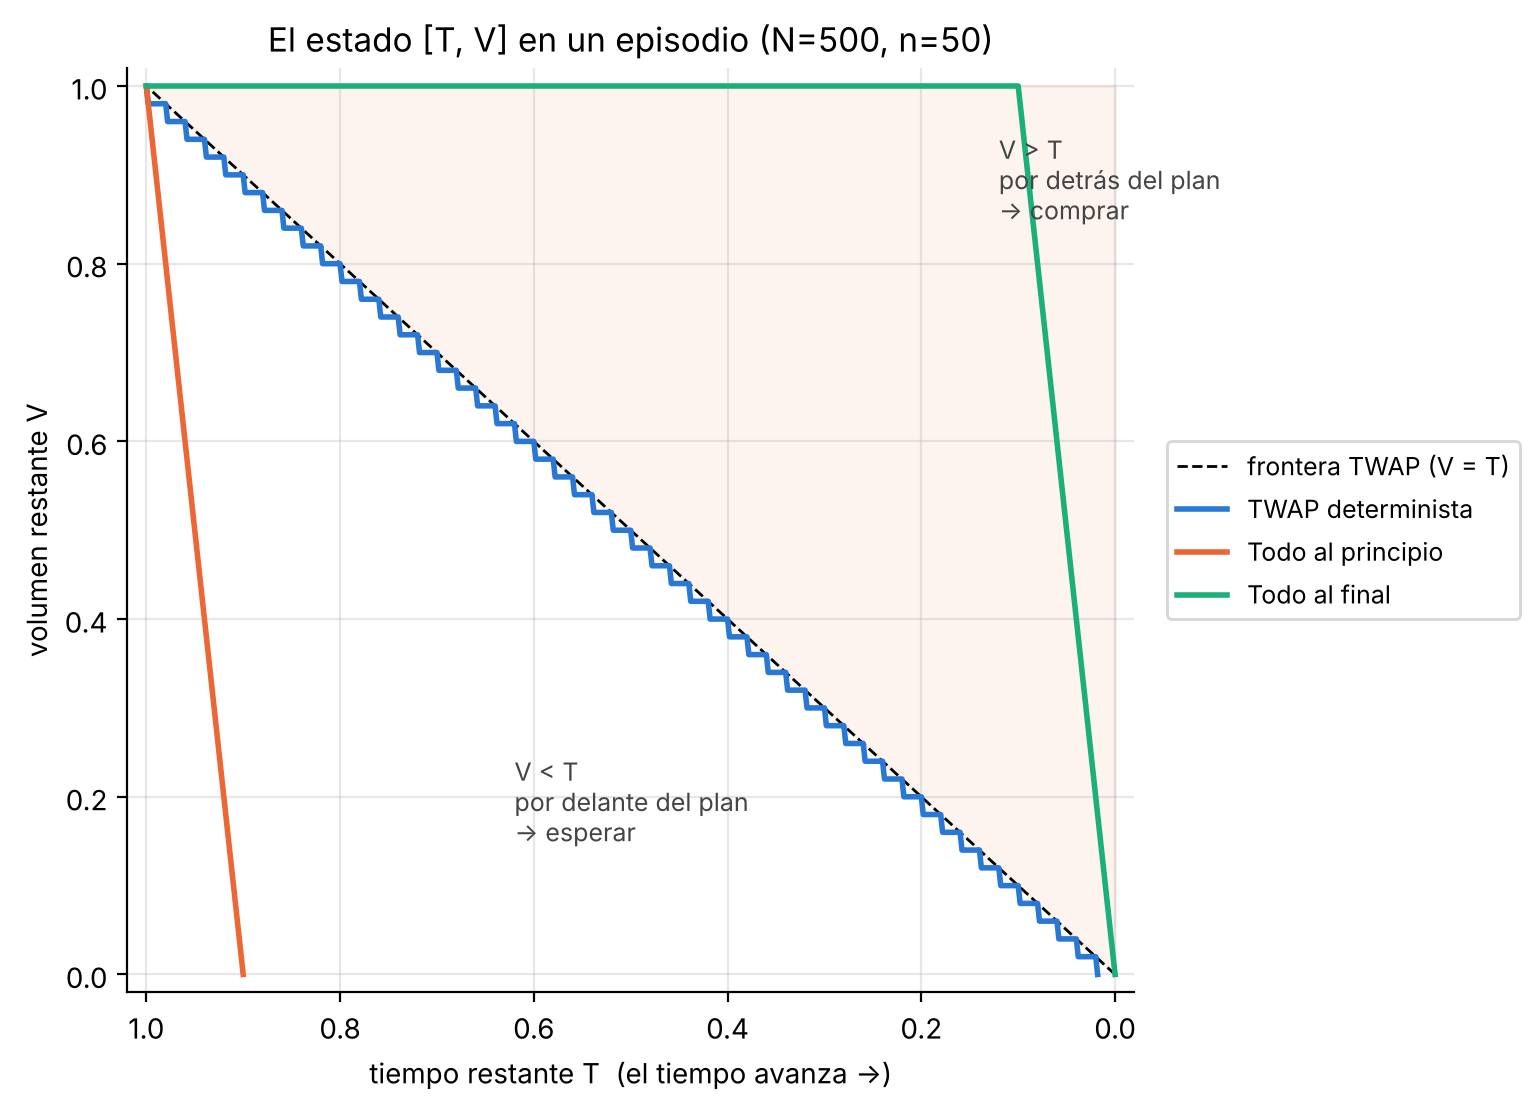

In [4]:
cfg = GRID[13]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.fill_between([0, 1], [0, 1], [1, 1], color=C["naranja"], alpha=0.08)
ax.text(0.12, 0.85, "V > T\npor detrás del plan\n→ comprar", fontsize=9, color="#444")
ax.text(0.62, 0.15, "V < T\npor delante del plan\n→ esperar", fontsize=9, color="#444")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="frontera TWAP (V = T)")
for (pname, col) in [("TWAP determinista", C["azul"]), ("Todo al principio", C["naranja"]), ("Todo al final", C["aqua"])]:
    env = BestExecutionEnv(train, seed=0)
    pol = Policy(POLICIES[pname], env)
    s = env.reset(**{k: cfg[k] for k in ("day", "start_pos", "n_bins", "vol_care")})
    S = [s]
    while True:
        s, r, done, _ = env.step(pol.act(s))
        S.append(np.array([env.time_left(), env.vol_left()]))
        if done:
            break
    S = np.array(S)
    ax.plot(S[:, 0], S[:, 1], color=col, lw=2, label=pname)
ax.set_xlim(1.02, -0.02); ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("tiempo restante T  (el tiempo avanza →)"); ax.set_ylabel("volumen restante V")
ax.set_title(f"El estado [T, V] en un episodio (N={cfg['n_bins']}, n={cfg['vol_care']})")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
pl.save(fig, "ej2_estado_plano")

El TWAP determinista **zigzaguea pegado a la diagonal**: cada compra baja V en 1/n y cada paso baja T en 1/N, así que se
mueve en escalones de ≈10 pasos alrededor de `V = T`. Las otras dos se alejan todo lo posible: una acaba en n pasos
(baja en vertical) y la otra no compra hasta el final (avanza en horizontal). El objetivo del agente es aprender a
quedarse en la diagonal **sin que se le diga la regla**, solo a través de la recompensa.

## 3. Parte 1 · La recompensa

### 3.1 Qué se le pide a la recompensa

Del material de clase (`docs/teoria/03_recompensas_y_descuento.md`) salen cuatro criterios:

| Criterio | Qué significa aquí |
|---|---|
| **Alineada con el objetivo** | Lo que más paga debe ser un reparto uniforme en el tiempo |
| **Predecible desde el estado** | El agente solo ve `[T, V]`: la recompensa debe poder anticiparse con eso |
| **Densa** | Una señal por paso, no solo al final de ~500 pasos |
| **Sin atajos** | Que no exista una política degenerada que cobre casi lo mismo que la buena |
| **Que no dicte la acción** | El profesor lo quiere "por recompensas": premiar el resultado, no copiar la regla |

### 3.2 Opciones consideradas

| Recompensa | Fórmula | Alineada | Predecible | Densa | Sin atajos | No dicta la acción |
|---|---|---|---|---|---|---|
| `Default` (ej. 1) | (VWAP episodio − precio) / VWAP si compra | ✗ (§1) | ✗ | ✓ | ✗ | ✓ |
| Final dispersa | −error máximo de seguimiento, solo al terminar | ✓ | ✓ | ✗ | ✓ | ✓ |
| `TWAPRule` (control) | +1 si la acción coincide con la regla, −1 si no | ✓ | ✓ | ✓ | ✓ | **✗** |
| `Tracking` | −mín(\|desviación\|, c) / c en cada paso | ✓ | ✓ | ✓ | **✗** (§1) | ✓ |
| **`TrackingCierre`** (elegida) | `Tracking` + cierre de los pasos que faltan | ✓ | ✓ | ✓ | ✓ | ✓ |

`TWAPRule` se entrena igualmente como **control**: es aprendizaje supervisado disfrazado (la recompensa ya contiene la
respuesta), y sirve para comprobar que la red tiene capacidad para aprender la frontera.

### 3.3 La recompensa elegida

En cada paso, tras ejecutar la acción, se mide la desviación respecto al plan TWAP en títulos:

$$d_{t+1} = e_{t+1} - (t+1)\,\frac{n}{N}, \qquad r_t = -\frac{\min\left(|d_{t+1}|,\ c\right)}{c} \in [-1, 0], \qquad c = 20$$

Y si la orden se completa en el paso t_f < N, se añade una **penalización de cierre** con los pasos que faltan, como si
el agente se quedara quieto con lo ejecutado, descontados con el γ del agente:

$$r_{\text{cierre}} = \sum_{k=1}^{N - t_f} \gamma^{k}\, r\!\left(e_{t_f},\ t_f + k\right)$$

Por qué cada pieza:

- **El término de seguimiento** no dice qué hacer, solo qué es "ir bien": comprar de más o de menos aleja del plan.
  Es denso, local y factible: depende de la acción y de algo que el estado contiene (`d = n·(T − V)`).
- **El recorte c** acota la recompensa en [−1, 0], para que la escala no dependa del tamaño de la orden ni del desastre
  de los primeros episodios. Pero el valor de c decide **cuánta información** lleva la recompensa: lo que esté a más de c
  títulos del plan "es igual de malo", y en esa zona la recompensa no indica hacia dónde volver. La idea de partida era
  c = 5, para que la red se concentrara cerca de la diagonal; el barrido de §6 (c ∈ {1, 5, 20}) la **desmiente**: con c = 5
  el agente es inestable entre semillas y con c = 1 no aprende, porque casi todo lo que ve en los primeros episodios, lejos
  del plan, cobra el mismo −1. Con **c = 20** la recompensa sigue siendo informativa en casi todo el rango (la desviación
  máxima posible es de ~45 títulos) y el agente replica el TWAP en todas las semillas.
- **El cierre** existe por la tabla de §1: al completar la orden el episodio termina y, con él, la penalización. Comprar
  todo al principio cuesta como mucho n pasos de −1, y un TWAP perfecto paga un poco en cada uno de sus ~10·n pasos. Sin
  descontar, los dos retornos se parecen y con γ alto (0,99) **el atajo es una solución casi tan buena como el TWAP**.
  Con el cierre, el retorno descontado es exactamente el que tendría el episodio si durara siempre N pasos, que es como
  se mide el error de seguimiento. Usa el γ del agente para que el valor del cierre sea coherente con cómo se descuenta el
  resto del episodio.

### 3.4 Qué comportamiento cabe esperar (y por qué no será perfecto)

Con γ pequeño el agente optimiza casi solo la recompensa del paso siguiente. Comprar mejora esa recompensa cuando
`|d + 1| < |d|`, es decir, cuando va por detrás del plan más de medio título. En términos del estado:

$$\text{comprar} \iff V_t - T_t > \frac{0{,}5 - \rho}{n} \approx \frac{0{,}4}{n}$$

Es una frontera **paralela a la diagonal y casi pegada a ella**, que redondea al entero más cercano al plan: el oráculo
miope de §1 la sigue y obtiene un error máximo de ~0,5 títulos, mejor que el TWAP determinista (~0,9). Pero el umbral
depende de n, que **no está en el estado**: para n = 30 es 0,013 y para n = 75, 0,005. El agente tiene que elegir una
única frontera para todos los tamaños, así que lo esperable es un error máximo **del orden de 1 título**, como el TWAP
determinista, no el 0,5 del oráculo. Añadir n al estado podría acercarlo al oráculo, pero no hace falta: el enunciado pide
un comportamiento similar al TWAP, no mejorarlo.

In [5]:
print(inspect.getsource(rw.TrackingCierre))

class TrackingCierre(Tracking):
    """Seguimiento del plan sin atajo por terminar antes (ej. 2).

    Con ``Tracking`` el episodio acaba al completar la orden y, con él, la penalización:
    comprar todo de golpe cuesta como mucho n pasos de -1 (el error está acotado), y un
    TWAP perfecto paga ~0,05-0,1 por paso durante N ≈ 10·n pasos. Sin descontar, los dos
    retornos se parecen (-47,6 frente a -43,0 en la rejilla) y con γ alto el agente
    aprende a acabar pronto.

    Al terminar antes de N, ``done`` cobra los pasos que faltan como si el agente se
    quedara quieto con lo ejecutado, descontados con el γ del agente:

        r_cierre = Σ_{k=1}^{N-t} γ^k · r_seguimiento(e, t + k)

    (se suma a la recompensa del último paso, de ahí γ^k). Así el retorno descontado es el mismo que si el episodio durara siempre N pasos, que es
    como se mide el error de seguimiento (protocol.episode_metrics).
    """
    name = "seguimiento_cierre"

    def __init__(self, gamma: float = 0.9, c

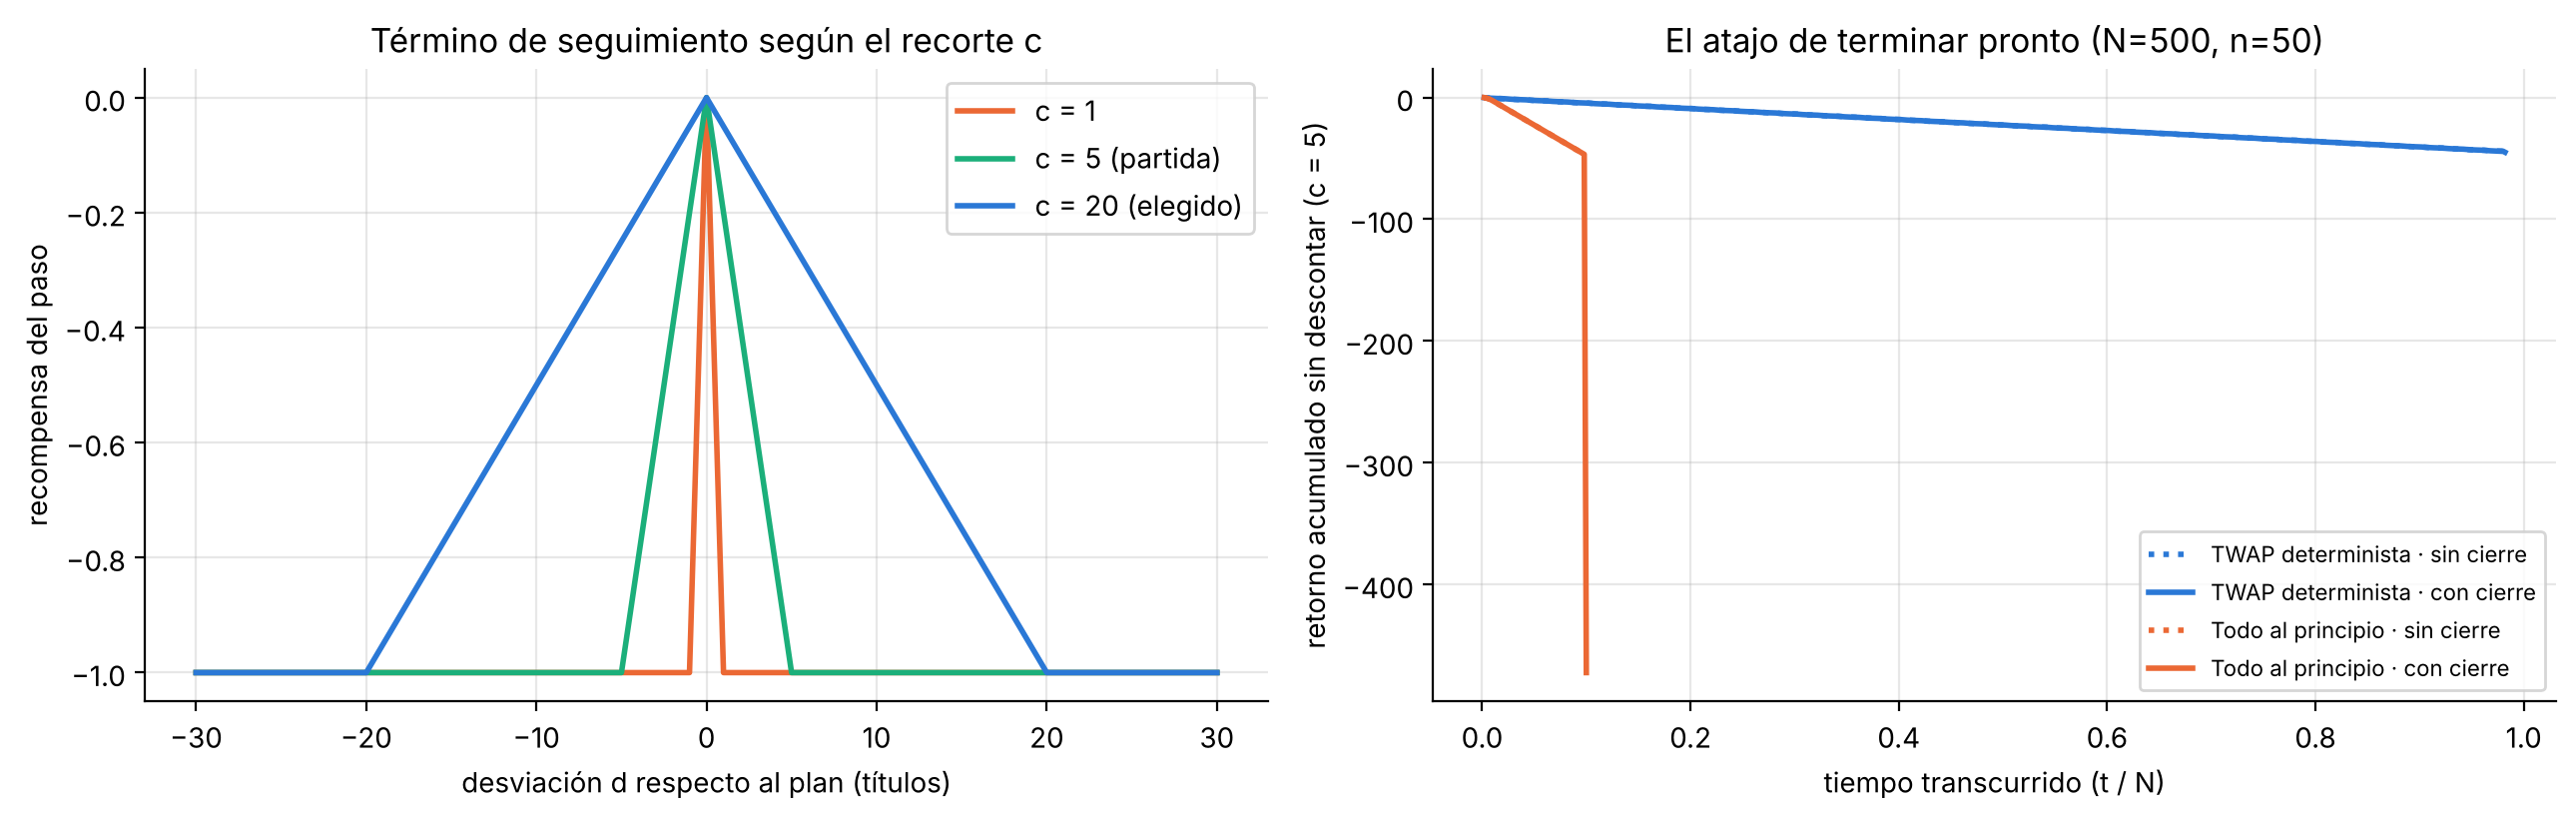

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
d = np.linspace(-30, 30, 601)
for c_, col in [(1, C["naranja"]), (5, C["aqua"]), (20, C["azul"])]:
    axes[0].plot(d, -np.minimum(np.abs(d), c_) / c_, color=col,
                 label=f"c = {c_}" + {1: "", 5: " (partida)", 20: " (elegido)"}[c_])
axes[0].set_xlabel("desviación d respecto al plan (títulos)"); axes[0].set_ylabel("recompensa del paso")
axes[0].set_title("Término de seguimiento según el recorte c"); axes[0].legend()

cfg = GRID[13]
for pname, col in [("TWAP determinista", C["azul"]), ("Todo al principio", C["naranja"])]:
    for rname, make, ls in [("sin cierre", lambda: rw.Tracking(clip=5.0), ":"),
                            ("con cierre", lambda: rw.TrackingCierre(gamma=1.0, clip=5.0), "-")]:
        env = BestExecutionEnv(train, reward=make(), seed=0)
        r = rollout(env, Policy(POLICIES[pname], env), cfg)
        axes[1].plot(np.arange(1, len(r) + 1) / cfg["n_bins"], np.cumsum(r), ls, color=col, label=f"{pname} · {rname}")
axes[1].set_xlabel("tiempo transcurrido (t / N)"); axes[1].set_ylabel("retorno acumulado sin descontar (c = 5)")
axes[1].set_title(f"El atajo de terminar pronto (N={cfg['n_bins']}, n={cfg['vol_care']})"); axes[1].legend(fontsize=8)
fig.tight_layout(); pl.save(fig, "ej2_recompensa")

**Izquierda:** con c = 1 la recompensa es casi binaria (en el plan o fuera de él): lejos de la diagonal no dice hacia dónde
volver. Con c = 20 es una pendiente que llega a casi todo el rango de desviaciones posibles.

**Derecha**, el atajo en un episodio, sin descontar y con el recorte de partida (c = 5). Sin cierre (punteado), comprar
todo al principio se para en −47 al décimo del episodio, cerca del −43 que el TWAP acumula durante el episodio entero. Con
cierre (continuo), en el paso en que completa la orden cobra de golpe los ~450 pasos que faltaban, adelantado ~45 títulos
respecto al plan, y cae por debajo de −400. Al TWAP el cierre no le cambia casi nada, porque acaba al 98 % del tiempo.

## 4. Parte 1 · ¿Aprende?

Configuración final de entrenamiento. Sale del barrido de §6, que parte de una configuración razonada a priori (c = 5,
buffer de 50.000) y la corrige con los datos:

| Parámetro | Valor | Parámetro | Valor |
|---|---|---|---|
| Algoritmo | Double DQN con Combined Experience Replay (ej. 1) | Red | 2 → 32 → 32 → 2, ReLU |
| γ | 0,9 | α (Adam) | 0,001 |
| Buffer | 10.000 experiencias | Batch | 64 |
| Recorte de la recompensa c | 20 títulos | | |
| Aprender cada | 8 pasos | Copiar red objetivo cada | 1.000 pasos |
| Episodios | 300 (+25 aleatorios de llenado) | ε | lineal de 1 a 0,05 en 150 episodios (el ej. 3 lo cambia) |

Cada 25 episodios se hace una **evaluación greedy** (sin exploración) en la rejilla: así la curva de aprendizaje mide la
política de verdad, no la mezcla con acciones aleatorias que hay en la recompensa de entrenamiento.

Se entrenan tres agentes con la misma semilla: el elegido (`TrackingCierre`), `Tracking` sin cierre y el control
`TWAPRule`.

In [7]:
# Configuración de partida del barrido (§6) y configuración final
BASE0 = dict(reward="cierre", gamma=0.9, clip=5.0, buffer_size=50_000, learn_after=8, update_target_after=1000,
             nepisodes=300, alpha=1e-3, batch_size=64, hidden_neurons=32)
FINAL = {**BASE0, "clip": C_FINAL, "buffer_size": 10_000}

def make_reward(cfg):
    if cfg["reward"] == "cierre":
        return rw.TrackingCierre(gamma=cfg["gamma"], clip=cfg["clip"])
    if cfg["reward"] == "seguimiento":
        return rw.Tracking(clip=cfg["clip"])
    if cfg["reward"] == "regla":
        return rw.TWAPRule()
    raise ValueError(cfg["reward"])

def run(cfg=FINAL, seed=0):
    # Entrena un DDQN con la configuración dada y lo evalúa (greedy) en la rejilla
    pr.set_seeds(seed)
    reward = make_reward(cfg)
    env = BestExecutionEnv(train, reward=reward, seed=seed)
    agent = DDQNAgent(env, gamma=cfg["gamma"], epsilon=1.0, alpha=cfg["alpha"], batch_size=cfg["batch_size"],
                      buffer_size=cfg["buffer_size"], hidden_neurons=cfg["hidden_neurons"], seed=seed)
    pr.fill_buffer(agent, env, 25)                                     # D-1.1
    exploration = ex.LinearDecay(1.0, 0.05, nepisodes=cfg["nepisodes"])
    ep, ev = pr.train(agent, env, cfg["nepisodes"], exploration, cfg["learn_after"], cfg["update_target_after"],
                      eval_data=train, eval_grid=GRID, eval_every=25, eval_reward=reward, verbose=False)
    res = pr.evaluate(agent, train, GRID, reward=reward)
    return agent, ep, ev, res

agent, ep, ev, res = run(FINAL)
agent.save(pr.MODELS / "ej2_ddqn.pt")
pr.save_df(ep, "ej2_train"); pr.save_df(ev, "ej2_evals"); pr.save_df(res, "ej2_eval_train")
agent_tr, ep_tr, ev_tr, res_tr = run({**FINAL, "reward": "seguimiento"})
agent_rule, ep_rule, ev_rule, res_rule = run({**FINAL, "reward": "regla"})

In [8]:
COLS = ["completed_mean", "pending_mean", "t_fin_mean", "max_err_mean", "max_err_std", "mean_err_mean",
        "n_buys_mean", "slippage_bps_mean", "slippage_bps_std", "slippage_vs_twap_bps_mean"]
twap_grid = pr.load_df("00_twap_grid")
oraculo = ref[(ref.recompensa == "Tracking c=5") & (ref.política == "Oráculo miope")]
resumen = pd.DataFrame({
    "DDQN · TrackingCierre (elegido)": pr.summarize(res),
    "DDQN · Tracking (sin cierre)": pr.summarize(res_tr),
    "DDQN · TWAPRule (control)": pr.summarize(res_rule),
    "TWAP determinista": pr.summarize(twap_grid),
    "Aleatoria (p = ρ)": pr.summarize(pr.load_df("00_random_grid")),
}).reindex(COLS)
resumen.loc["max_err_mean", "Oráculo miope (conoce n)"] = oraculo.max_err.mean()
resumen.loc["t_fin_mean", "Oráculo miope (conoce n)"] = oraculo.t_fin.mean()
resumen.loc["mean_err_mean", "Oráculo miope (conoce n)"] = oraculo.mean_err.mean()
resumen.index = ["órdenes completas", "títulos pendientes", "acaba en (t/N)", "error máx. medio (títulos)",
                 "error máx. (desv.)", "error medio (títulos)", "compras", "slippage vs mercado (pb)",
                 "slippage (desv.)", "slippage vs TWAP (pb)"]
resumen.round(3)

,DDQN · TrackingCierre (elegido),DDQN · Tracking (sin cierre),DDQN · TWAPRule (control),TWAP determinista,Aleatoria (p = ρ),Oráculo miope (conoce n)
órdenes completas,1.000,1.000,1.000,1.000,0.481,NaN
títulos pendientes,0.000,0.000,0.000,0.000,2.407,NaN
acaba en (t/N),0.989,0.979,0.986,0.981,0.940,0.991
error máx. medio (títulos),0.900,0.998,0.913,0.900,7.180,0.500
error máx. (desv.),0.021,0.071,0.029,0.021,3.598,NaN
error medio (títulos),0.269,0.276,0.435,0.437,3.241,0.250
compras,49.889,49.889,49.889,49.889,47.481,NaN
slippage vs mercado (pb),-1.822,-1.787,-1.759,-1.774,-2.432,NaN
slippage (desv.),1.512,1.452,1.401,1.345,1.822,NaN
slippage vs TWAP (pb),-0.049,-0.014,0.014,0.000,-0.659,NaN


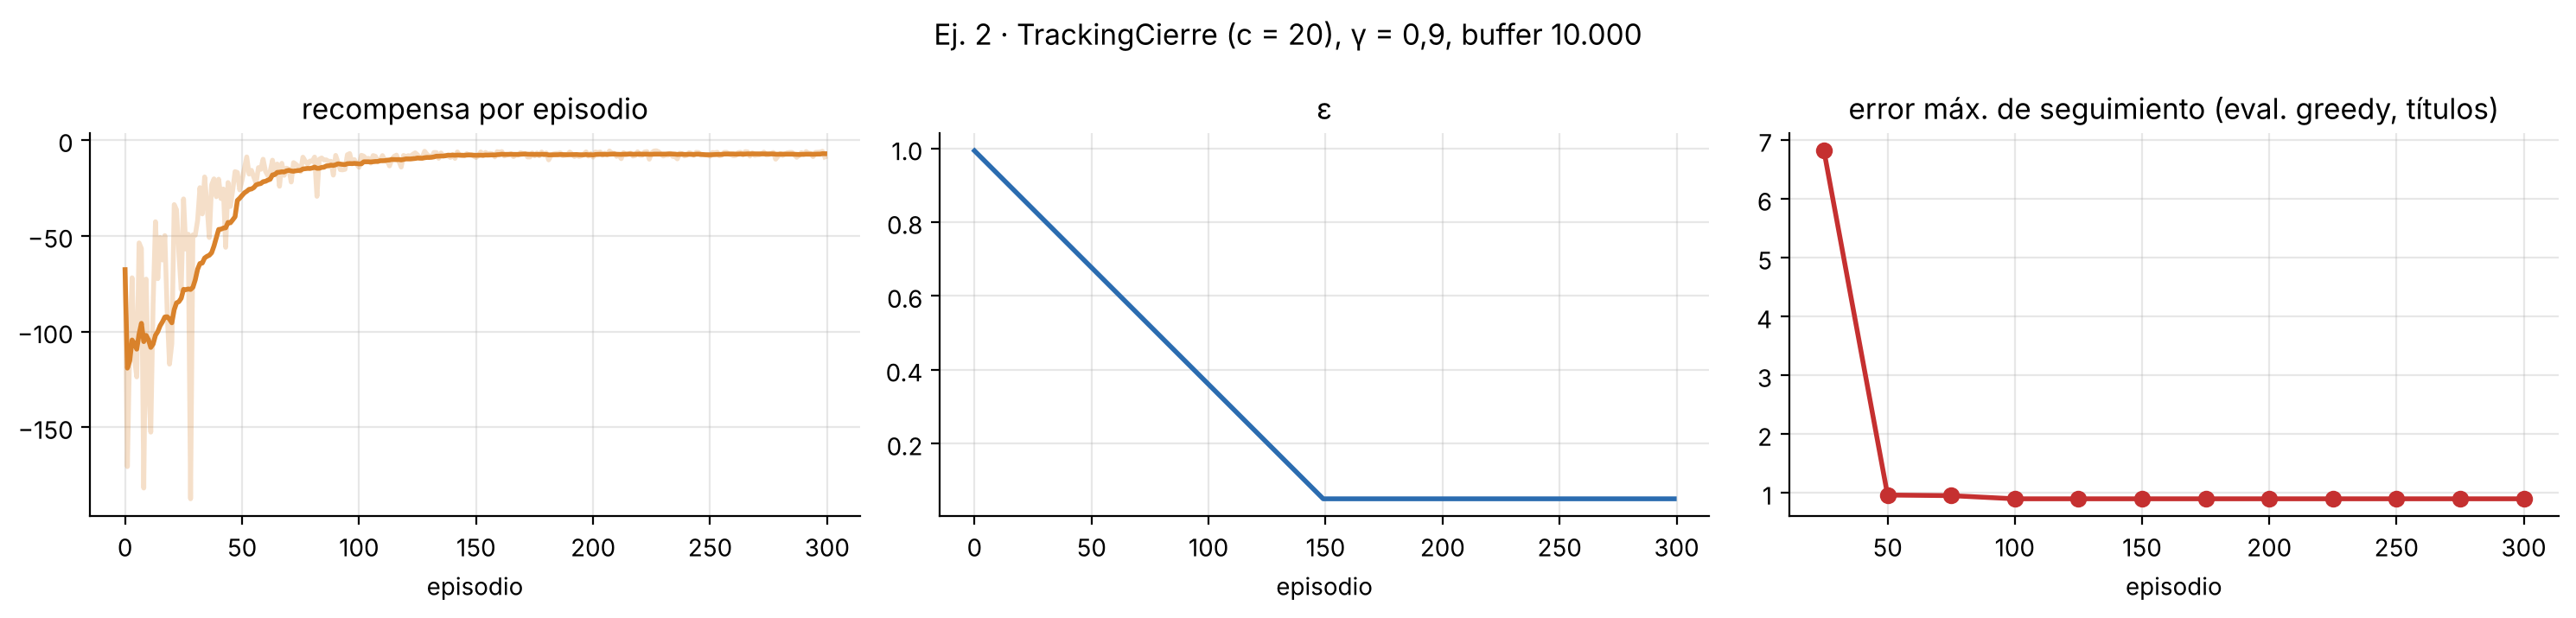

In [9]:
fig = pl.plot_training(ep, ev, title="Ej. 2 · TrackingCierre (c = 20), γ = 0,9, buffer 10.000", save="ej2_training")

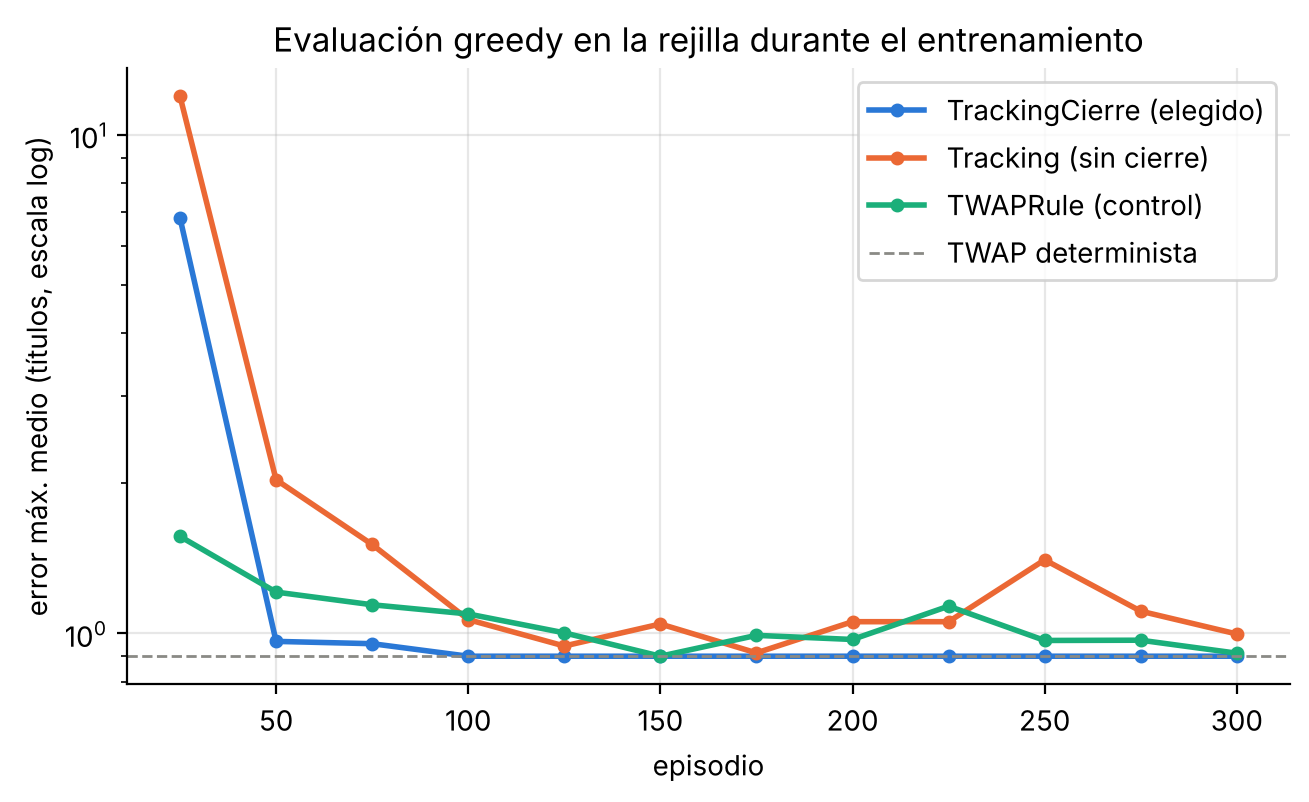

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for e_, lab, col in [(ev, "TrackingCierre (elegido)", C["azul"]), (ev_tr, "Tracking (sin cierre)", C["naranja"]),
                     (ev_rule, "TWAPRule (control)", C["aqua"])]:
    ax.plot(e_.episode, e_.max_err, "o-", ms=4, color=col, label=lab)
ax.axhline(twap_grid.max_err.mean(), color=C["gris"], ls="--", lw=1, label="TWAP determinista")
ax.set_yscale("log"); ax.set_xlabel("episodio"); ax.set_ylabel("error máx. medio (títulos, escala log)")
ax.set_title("Evaluación greedy en la rejilla durante el entrenamiento"); ax.legend()
pl.save(fig, "ej2_curvas_recompensas")

**Aprende, y replica el TWAP.** En los 27 episodios de la rejilla el agente final:

- **Completa todas las órdenes** y acaba de media al 98,9 % del tiempo (el TWAP determinista, al 98,1 %).
- Tiene un **error máximo de 0,90 títulos**, el mismo que el TWAP determinista, y un **error medio de 0,27 títulos frente a
  0,44**: va más pegado al plan que la regla. Se explica en §5.
- Hace las mismas compras (49,9 de media) y su VWAP difiere del del TWAP en −0,05 pb, es decir, nada. Sin impacto de mercado
  y con el mismo calendario de compras no puede haber diferencia de precio, y tampoco se buscaba.

**Va rápido.** En la evaluación greedy el error máximo baja de 6,8 títulos en el episodio 25 a 0,96 en el 50, y desde el
100 se queda en 0,90. La recompensa de entrenamiento (media móvil de 20) pasa de −94 a −12 en 100 episodios y se estabiliza
en ~−7 cuando ε llega al mínimo, en el episodio 150. Lo que queda por debajo de 0 es el coste de seguir un plan continuo
con compras enteras, más las acciones aleatorias del 5 % de ε.

**Comparación entre recompensas con la misma configuración:**

- **`Tracking` sin cierre** también llega (1,00 títulos), aunque más despacio y con altibajos. Con γ = 0,9 el descuento ya
  tapa casi todo el atajo (§1). El cierre se vuelve decisivo con γ más alto (§6) y, sobre todo, hace que la recompensa sea
  correcta por construcción en lugar de serlo gracias a un γ concreto.
- **El control `TWAPRule`** llega a 0,91. La red tiene capacidad de sobra para aprender la frontera, y la recompensa de
  seguimiento la encuentra igual de bien **sin que nadie le dé la regla**, que es lo que pedía el profesor.

## 5. Parte 1 · ¿Se comporta como un TWAP?

Tres comprobaciones, de lo visual a lo cuantitativo:

1. El gráfico del LAB (`plot_results`) en tres episodios con **día, hora, duración y tamaño distintos**, para compararlo con
   la figura de ejemplo del enunciado (`images/twap_model/twap_reproduction_dqn.png`).
2. Las trayectorias de los 27 episodios y la política aprendida sobre todo el plano `[T, V]`.
3. Las métricas por día, duración y tamaño, y la regularidad del intervalo entre compras.

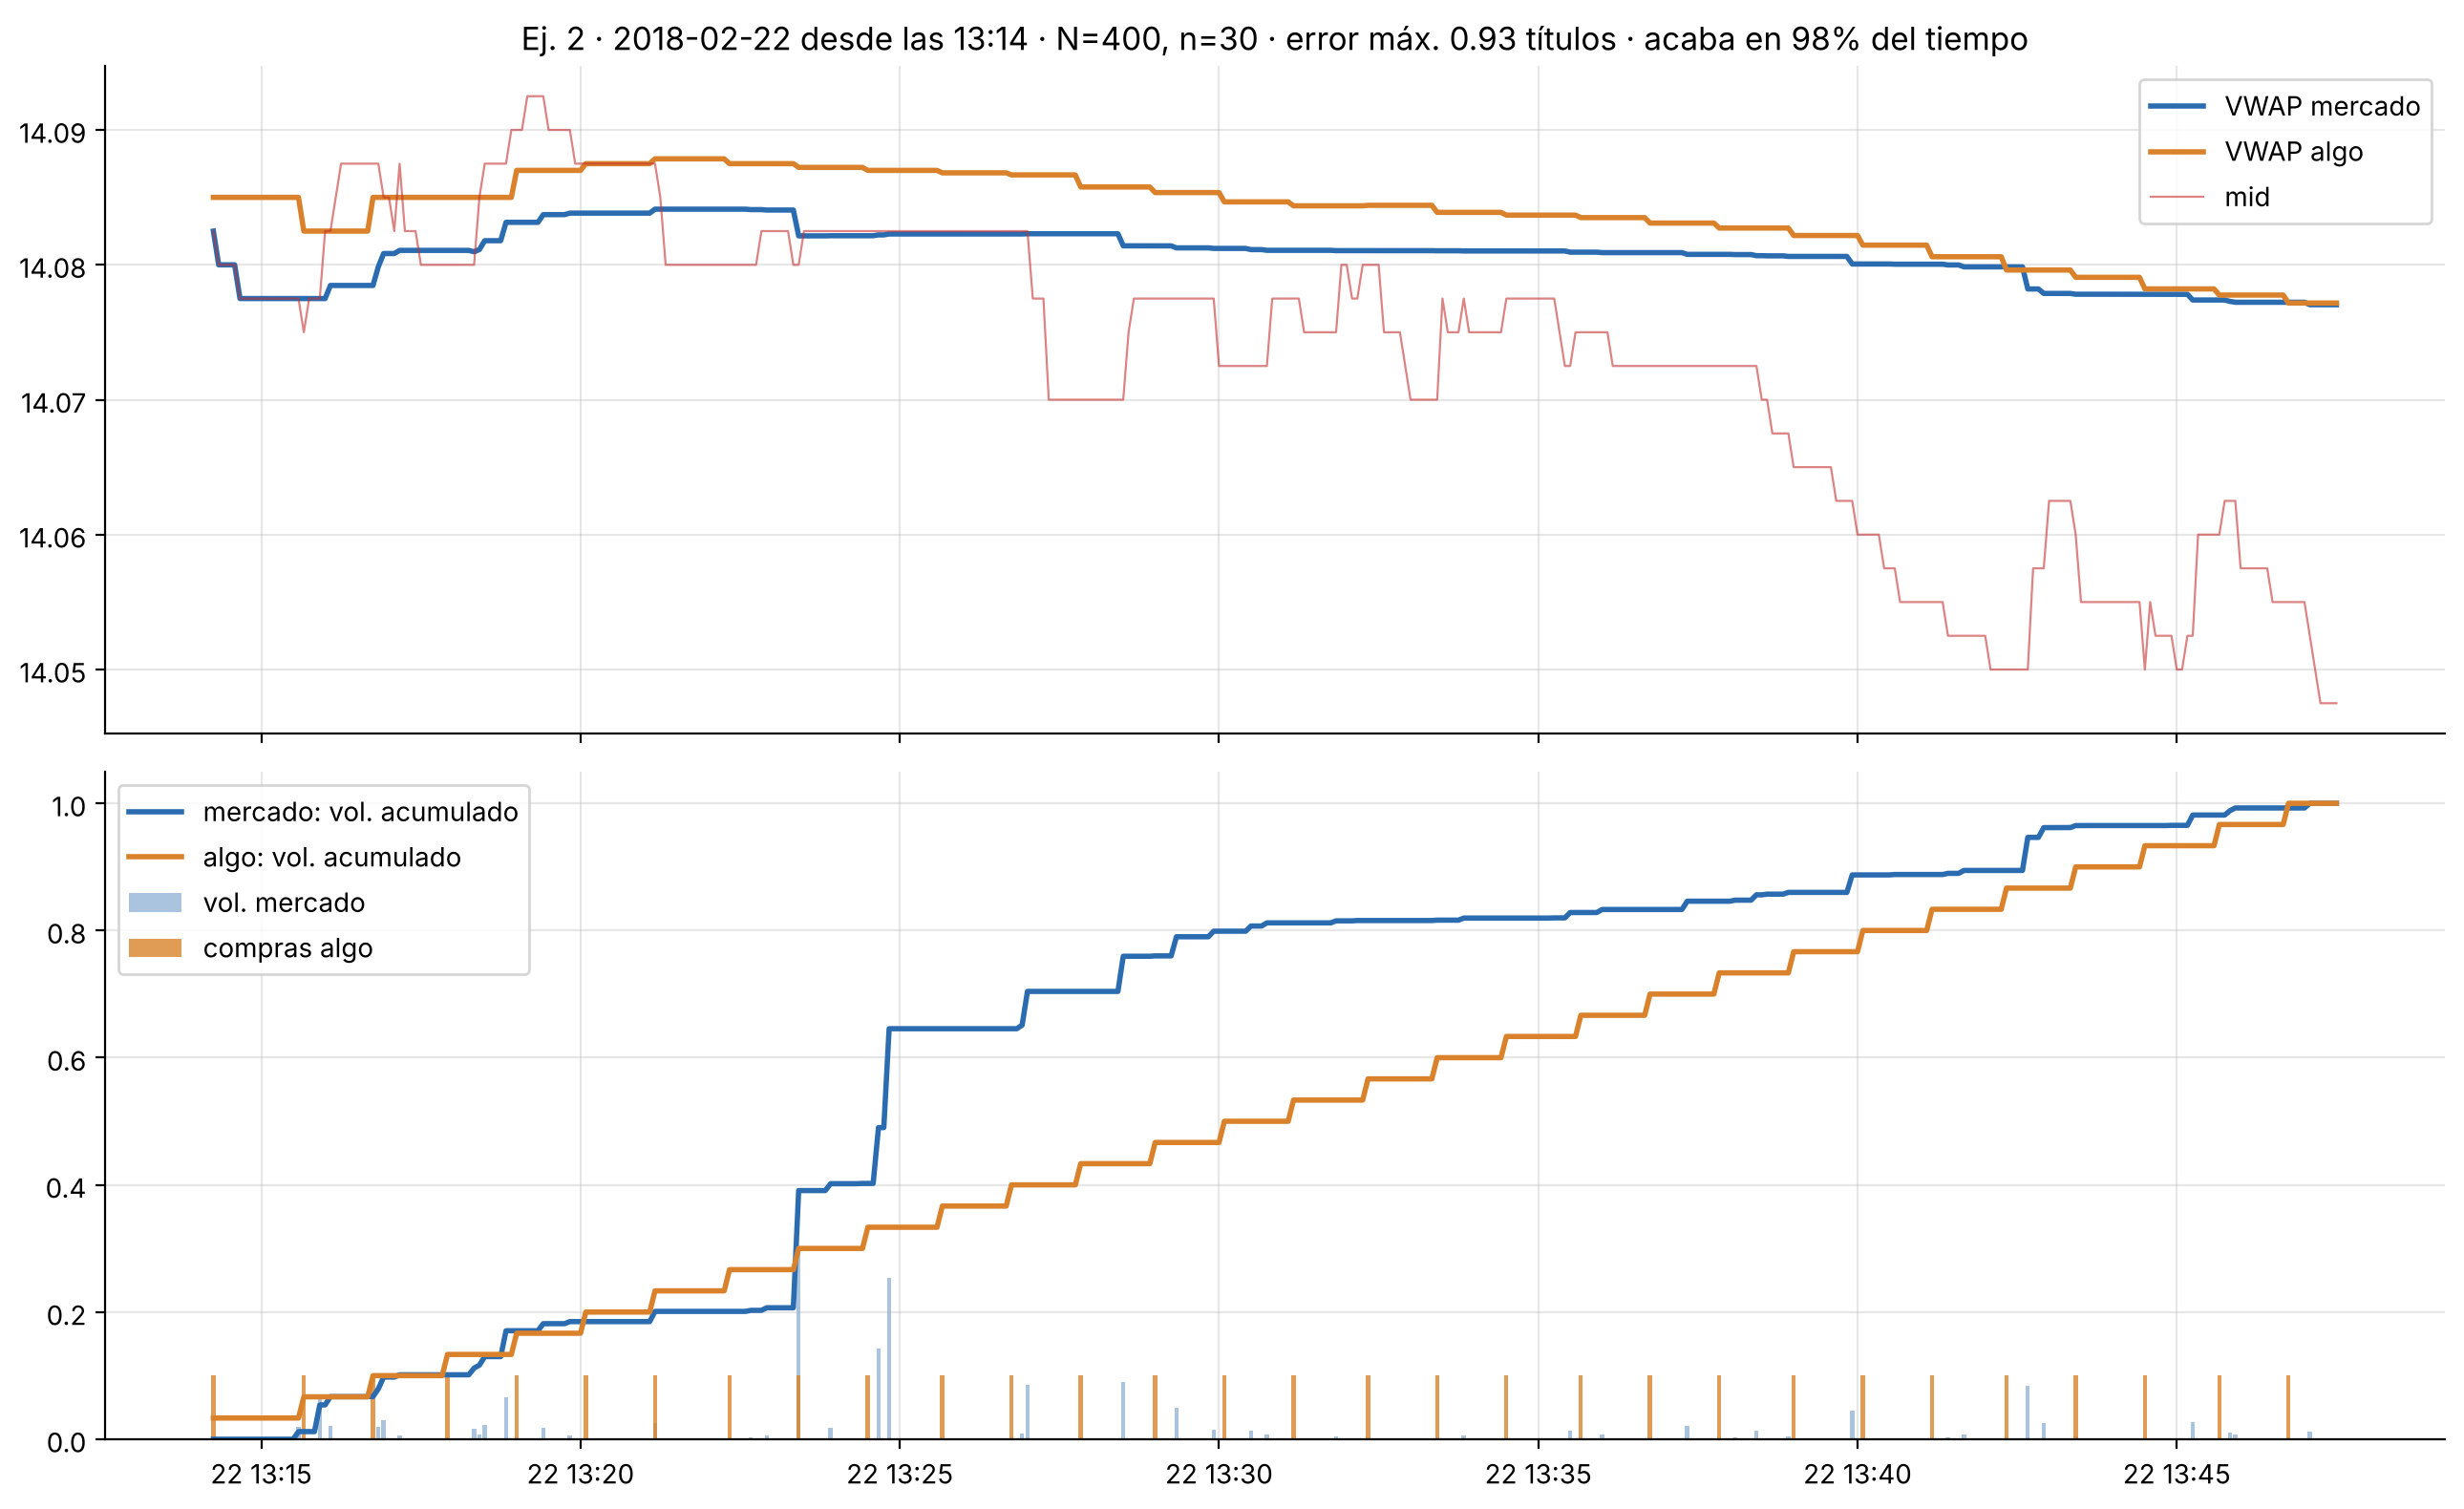

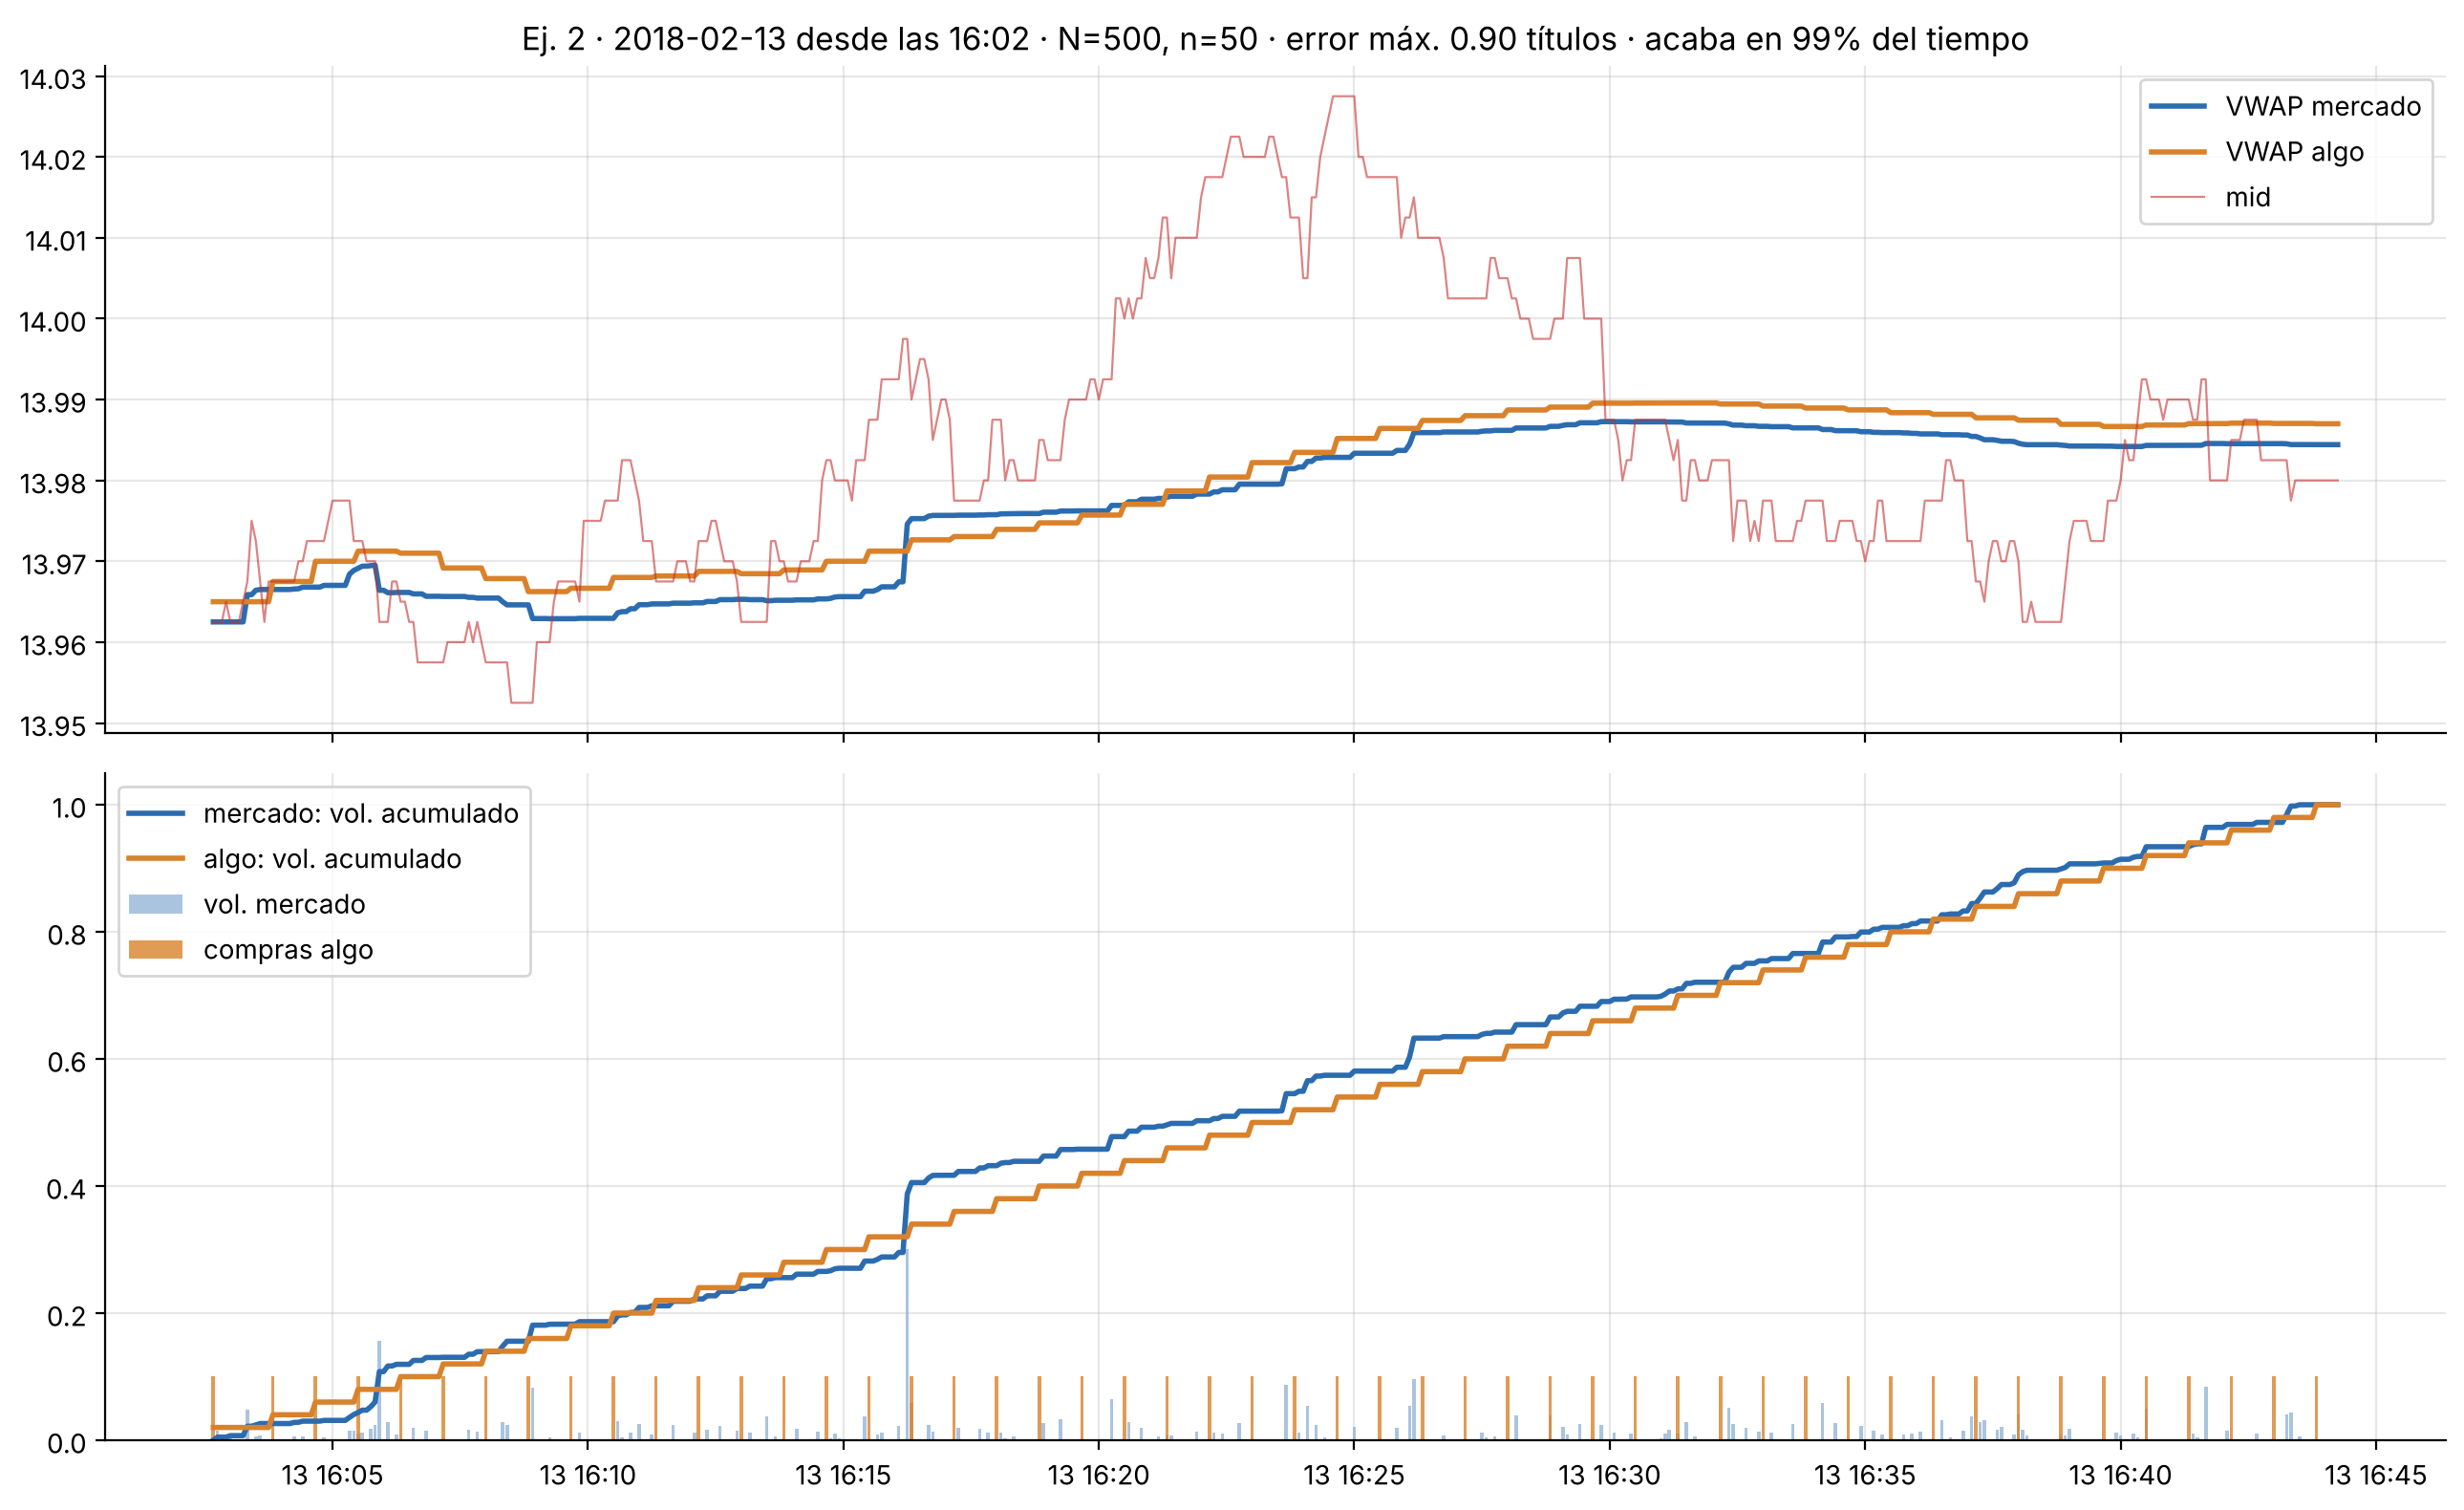

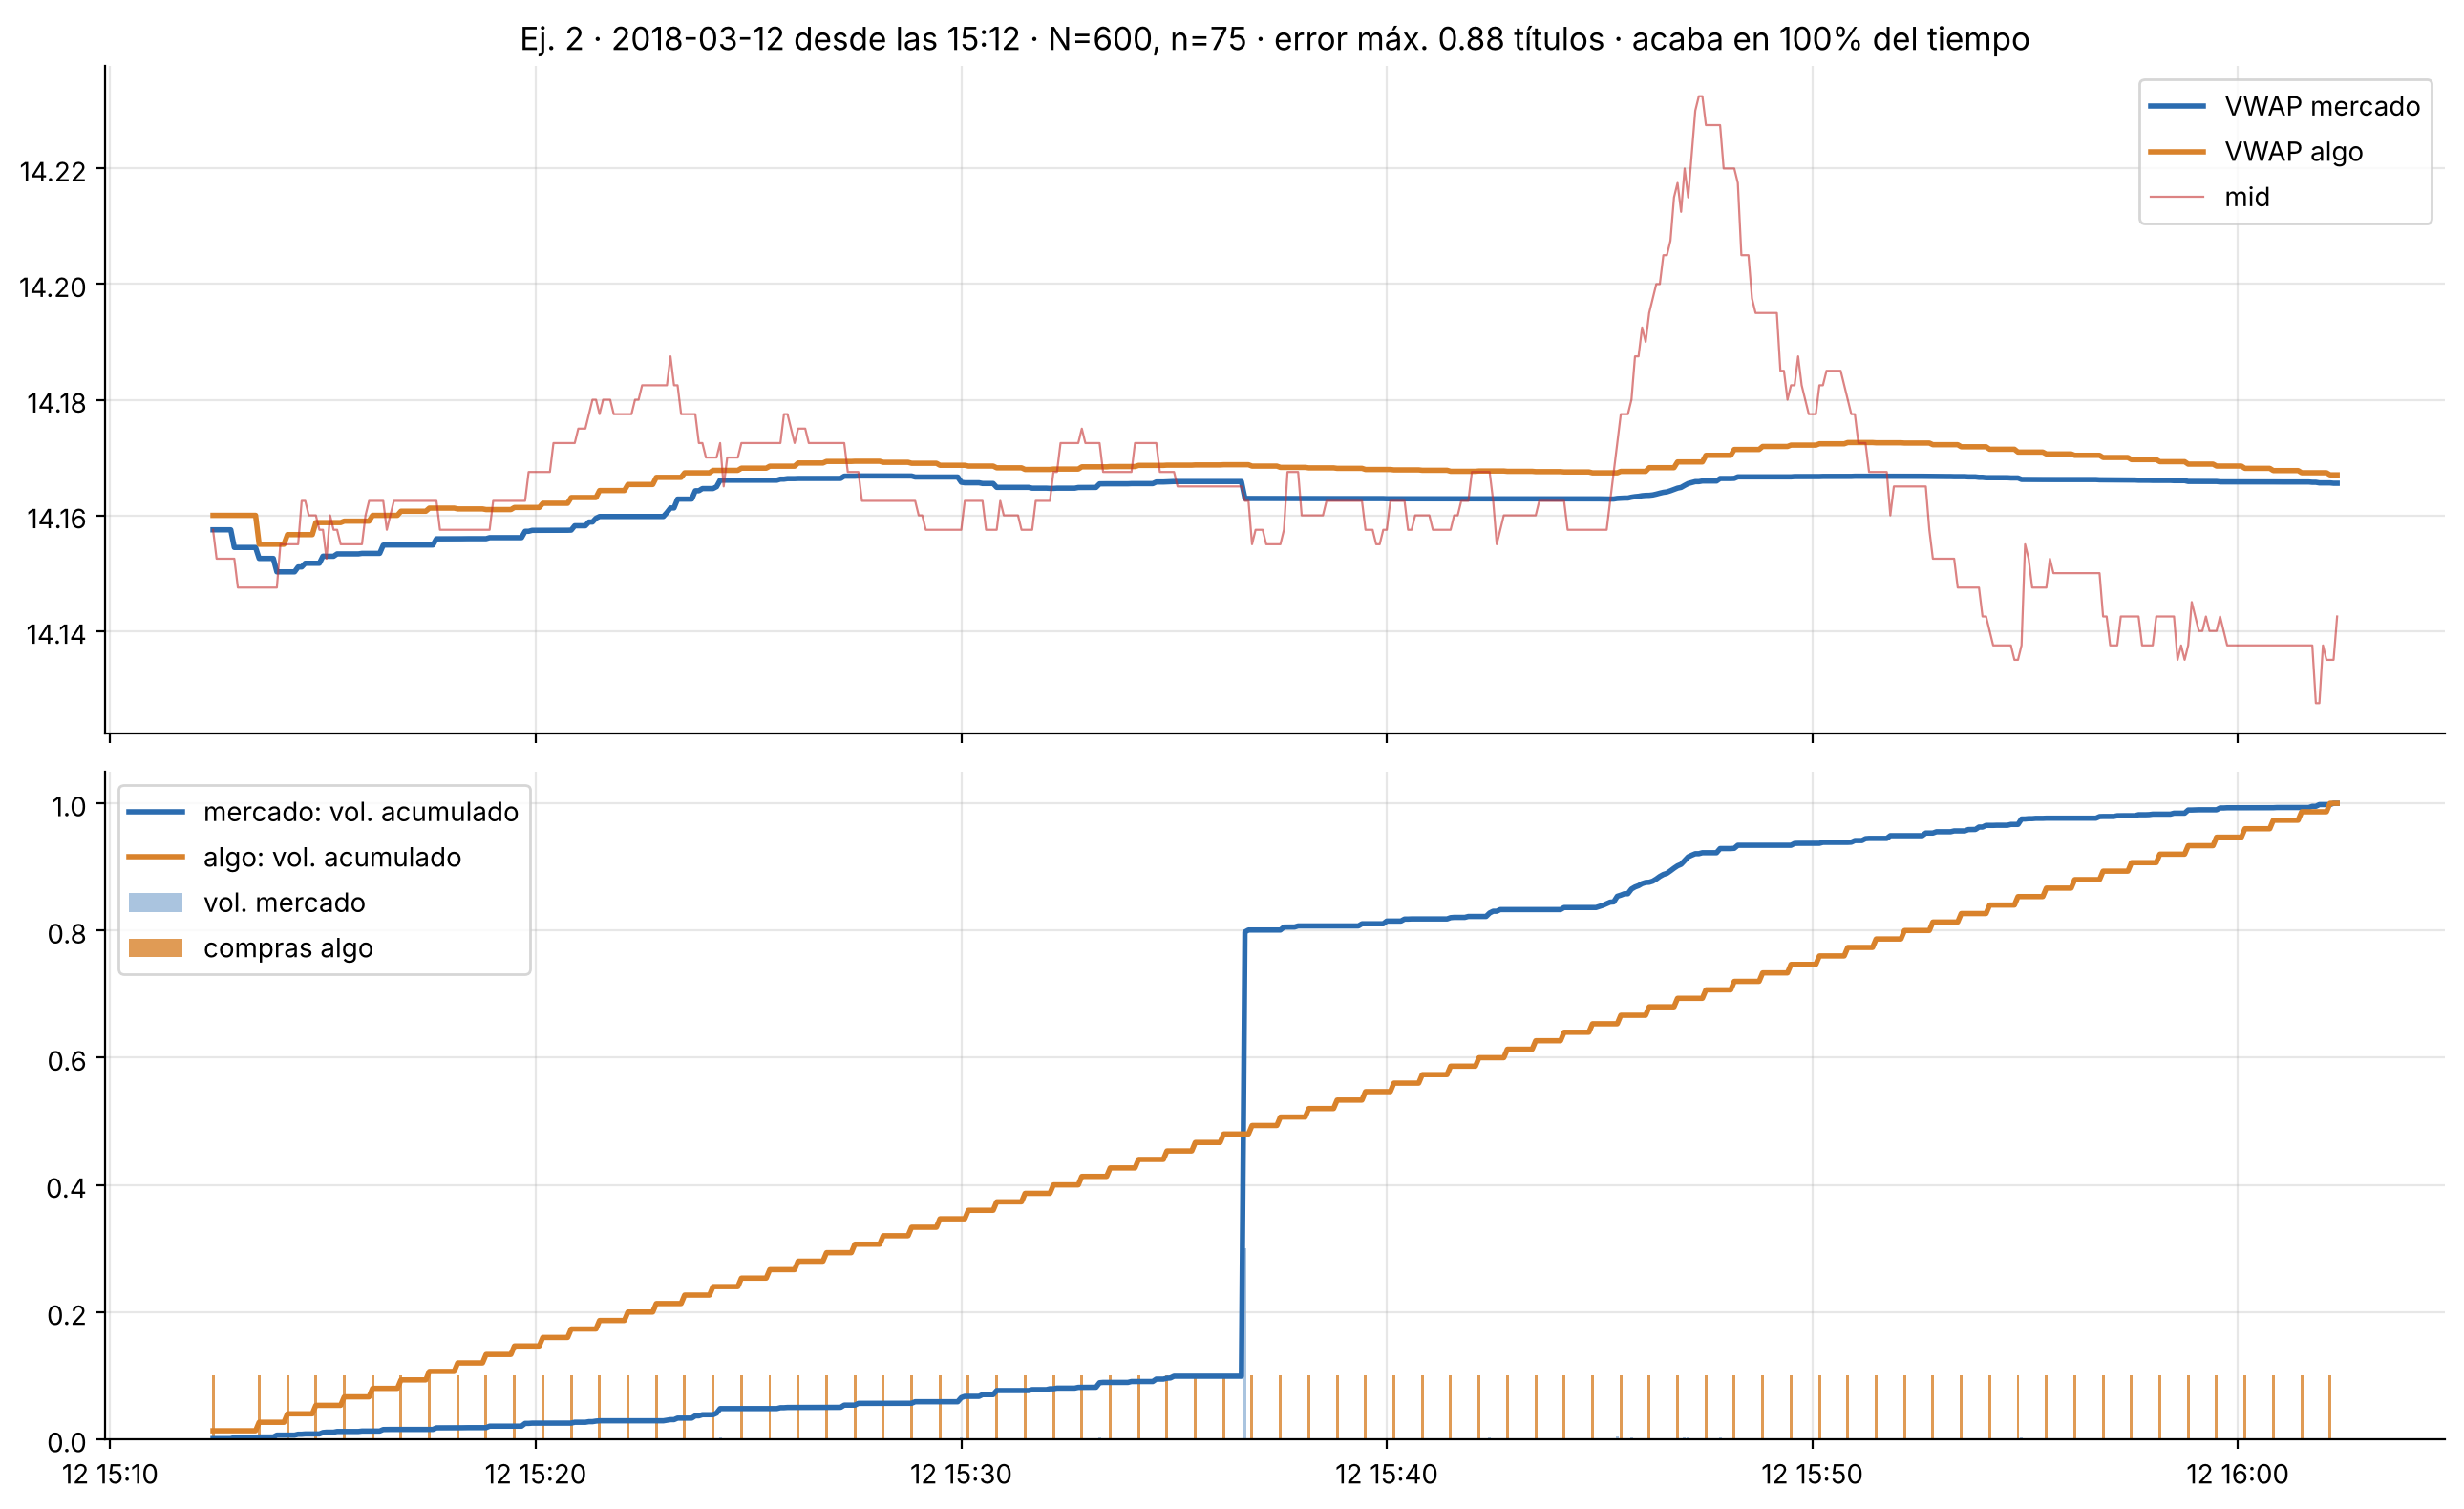

In [11]:
agent.set_trainable(False)
for i in (0, 13, 26):
    cfg = GRID[i]
    e = BestExecutionEnv(train, seed=0); agent.env = e
    pr.run_episode(e, agent, cfg)
    hora = str(e.episode.index[0])[11:16]
    m = pr.episode_metrics(e)
    pl.plot_results(e, title=f"Ej. 2 · {cfg['day']} desde las {hora} · N={cfg['n_bins']}, n={cfg['vol_care']} "
                             f"· error máx. {m['max_err']:.2f} títulos · acaba en {m['t_fin']:.0%} del tiempo",
                    save=f"ej2_episodio_{i}")

**Es la figura del enunciado** (`twap_reproduction_dqn.png`): el volumen acumulado del algoritmo (naranja, abajo) sube en
una **escalera casi diagonal** y las compras (barras naranjas) están **equiespaciadas**. Es así en un episodio corto de
primera hora con la orden mínima (N = 400, n = 30), en otro de 500 pasos con n = 50 y en uno largo a partir de las 15:12 con la
orden máxima (N = 600, n = 75).

El agente **ignora el volumen del mercado**, como debe hacer un TWAP. En el tercer episodio, el ~70 % del volumen del
mercado se cruza de golpe hacia las 15:37 (salto de la línea azul) y el algoritmo sigue comprando al mismo ritmo. Por eso su
VWAP (naranja, arriba) se separa algo del de mercado: el del mercado pondera por volumen y el del TWAP pondera por tiempo.
Esa diferencia es la que separa un TWAP de un VWAP, no un fallo del agente, y quien quiera reducirla tiene que meter
información del mercado en el estado (idea A del ej. 4).

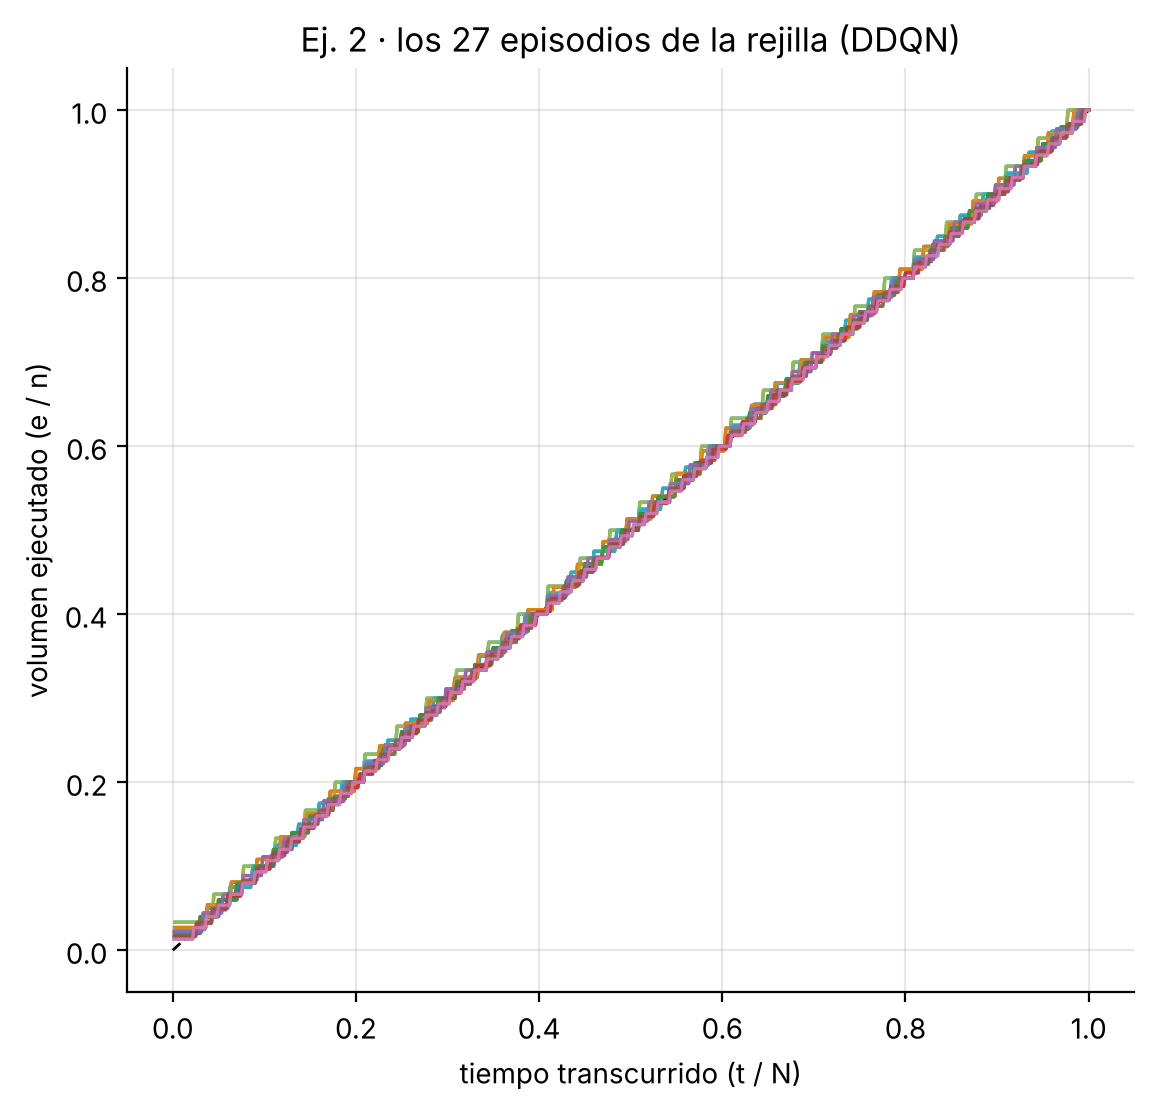

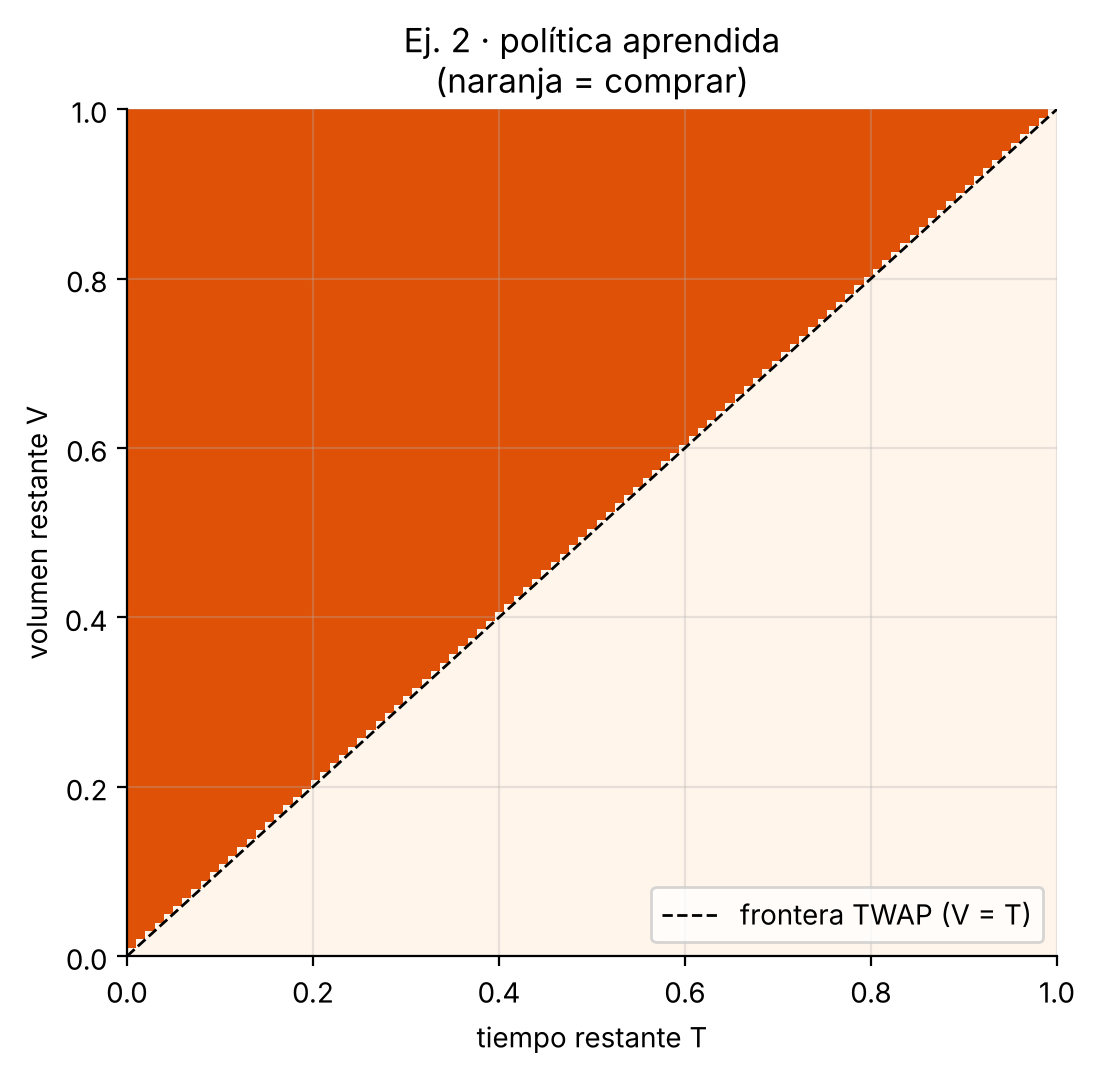

In [12]:
envs, envs_tw = [], []
for cfg in GRID:
    e = BestExecutionEnv(train, seed=0); agent.env = e; pr.run_episode(e, agent, cfg); envs.append(e)
    t = BestExecutionEnv(train, seed=0); pr.run_episode(t, TWAPAgent(t), cfg); envs_tw.append(t)
fig = pl.plot_trajectories(envs, title="Ej. 2 · los 27 episodios de la rejilla (DDQN)", save="ej2_trayectorias")
fig = pl.plot_policy_map(agent, title="Ej. 2 · política aprendida", save="ej2_politica")

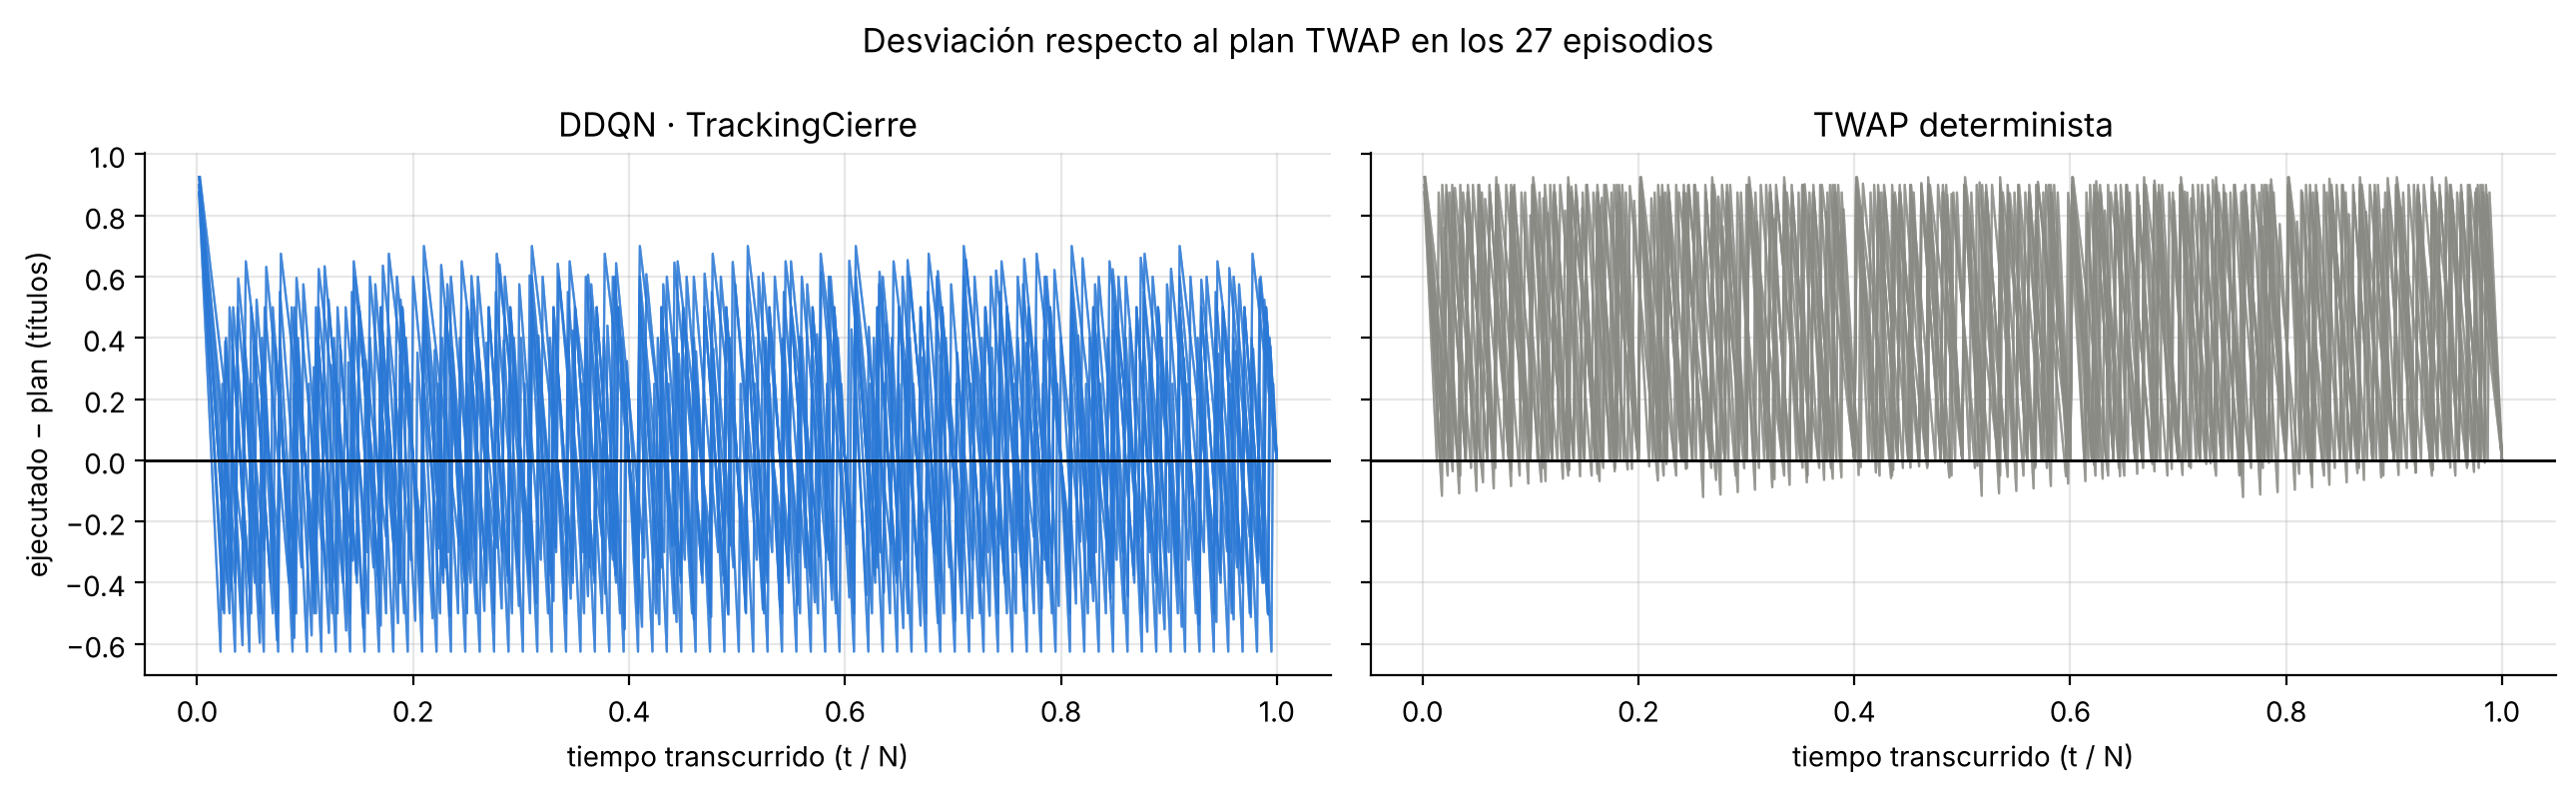

In [13]:
# Desviación respecto al plan a lo largo del episodio: DDQN frente al TWAP determinista
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, lst, tit in [(axes[0], envs, "DDQN · TrackingCierre"), (axes[1], envs_tw, "TWAP determinista")]:
    for e in lst:
        N, n = e.episode_bins, e.vol_care
        dev = pr.trajectory(e) - np.minimum(n, np.arange(1, N + 1) * n / N)
        ax.plot(np.arange(1, N + 1) / N, dev, lw=0.8, alpha=0.5, color=C["azul"] if lst is envs else C["gris"])
    ax.axhline(0, color="k", lw=1); ax.set_title(tit); ax.set_xlabel("tiempo transcurrido (t / N)")
axes[0].set_ylabel("ejecutado − plan (títulos)")
fig.suptitle("Desviación respecto al plan TWAP en los 27 episodios"); fig.tight_layout()
pl.save(fig, "ej2_desviacion")

In [14]:
# Requisito: distintos días, duraciones y tamaños
tw = twap_grid.assign(day=twap_grid.day.astype(str))
por_celda = res.pivot_table(index="N", columns="rho", values="max_err", aggfunc="mean")
por_celda_tw = tw.pivot_table(index="N", columns="rho", values="max_err", aggfunc="mean")
por_dia = pd.DataFrame({"DDQN error máx.": res.groupby("day").max_err.mean(),
                        "TWAP error máx.": tw.groupby("day").max_err.mean(),
                        "DDQN acaba en": res.groupby("day").t_fin.mean(),
                        "DDQN completas": res.groupby("day").completed.mean()})
display(Markdown("**Error máximo medio (títulos) por duración N y tamaño ρ = n/N · DDQN**")); display(por_celda.round(2))
display(Markdown("**Lo mismo para el TWAP determinista**")); display(por_celda_tw.round(2))
display(Markdown("**Por día**")); display(por_dia.round(3))
def max_err_desde(lst, k0=1):
    # error máximo sin los primeros k0 pasos (el paso 0 es una compra forzada, igual para todos)
    out = []
    for e in lst:
        N, n = e.episode_bins, e.vol_care
        dev = pr.trajectory(e) - np.minimum(n, np.arange(1, N + 1) * n / N)
        out.append(np.abs(dev[k0:]).max())
    return np.array(out)
sin0 = pd.DataFrame({"error máx. (todo el episodio)": [res.max_err.mean(), twap_grid.max_err.mean()],
                     "error máx. sin el paso 0": [max_err_desde(envs).mean(), max_err_desde(envs_tw).mean()],
                     "error medio": [res.mean_err.mean(), twap_grid.mean_err.mean()]},
                    index=["DDQN", "TWAP determinista"])
display(Markdown("**El paso 0 es una compra forzada (`force_first_buy`, como en el LAB): sin él**")); display(sin0.round(3))
print(f"Peor episodio de los 27: error máx. {res.max_err.max():.2f} títulos · todas completas: {res.completed.all()} "
      f"· acaba entre el {res.t_fin.min():.0%} y el {res.t_fin.max():.0%} del tiempo")

**Error máximo medio (títulos) por duración N y tamaño ρ = n/N · DDQN**

rho,0.075,0.100,0.125
N,,,
400,0.93,0.9,0.88
500,0.93,0.9,0.88
600,0.93,0.9,0.88


**Lo mismo para el TWAP determinista**

rho,0.075,0.100,0.125
N,,,
400,0.93,0.9,0.88
500,0.93,0.9,0.88
600,0.93,0.9,0.88


**Por día**

,DDQN error máx.,TWAP error máx.,DDQN acaba en,DDQN completas
day,,,,
2018-02-13,0.9,0.9,0.989,1.0
2018-02-22,0.9,0.9,0.989,1.0
2018-03-12,0.9,0.9,0.989,1.0


**El paso 0 es una compra forzada (`force_first_buy`, como en el LAB): sin él**

,error máx. (todo el episodio),error máx. sin el paso 0,error medio
DDQN,0.9,0.8,0.269
TWAP determinista,0.9,0.9,0.437


Peor episodio de los 27: error máx. 0.93 títulos · todas completas: True · acaba entre el 98% y el 100% del tiempo


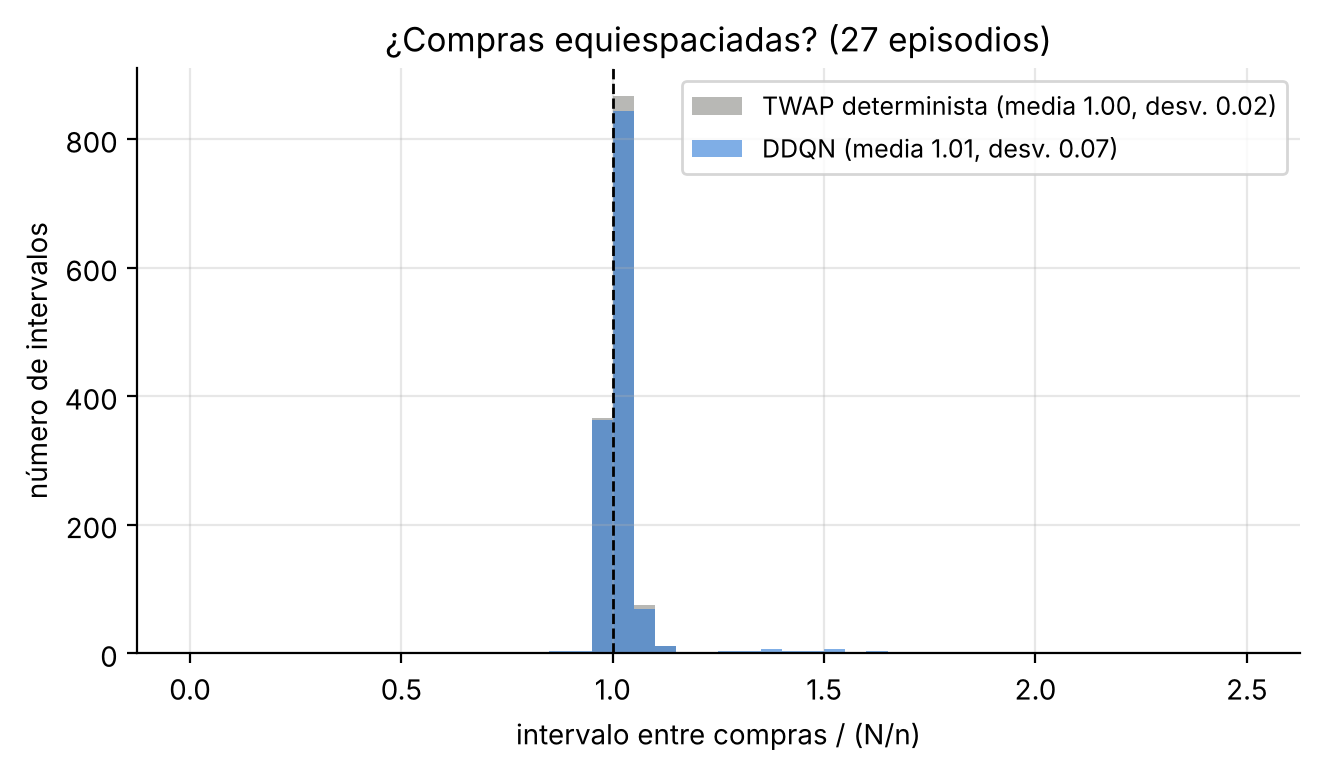

In [15]:
# Regularidad: intervalo entre compras normalizado por el intervalo ideal N/n (un TWAP perfecto da 1)
def gaps(lst):
    out = []
    for e in lst:
        b = np.flatnonzero(np.asarray(e.vol_hist) > 0)
        out.append(np.diff(b) / (e.episode_bins / e.vol_care))
    return np.concatenate(out)
g_dqn, g_tw = gaps(envs), gaps(envs_tw)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bins = np.linspace(0, 2.5, 51)
ax.hist(g_tw, bins=bins, color=C["gris"], alpha=0.6, label=f"TWAP determinista (media {g_tw.mean():.2f}, desv. {g_tw.std():.2f})")
ax.hist(g_dqn, bins=bins, color=C["azul"], alpha=0.6, label=f"DDQN (media {g_dqn.mean():.2f}, desv. {g_dqn.std():.2f})")
ax.axvline(1, color="k", lw=1, ls="--")
ax.set_xlabel("intervalo entre compras / (N/n)"); ax.set_ylabel("número de intervalos")
ax.set_title("¿Compras equiespaciadas? (27 episodios)"); ax.legend(fontsize=9)
pl.save(fig, "ej2_intervalos")

**Las 27 trayectorias van sobre la diagonal** y la política aprendida **coincide con la frontera `V = T` en todo el plano**,
incluso en zonas que un TWAP no visita nunca (muy por delante o muy por detrás del plan). Esto es efecto de c = 20: la
recompensa sigue dando señal lejos de la diagonal, así que el agente aprende qué hacer también ahí. Si en producción una
orden empezara desviada (un corte de conexión, un rechazo), volvería al plan.

**La diferencia con la regla está en la figura de desviaciones.** El TWAP determinista compra siempre que no va por delante
(`V ≥ T`), así que **siempre va adelantado**, entre 0 y +0,9 títulos. El agente oscila **centrado en el plan**, entre −0,6 y
+0,7: ha aprendido aproximadamente el comportamiento de "redondear al entero más cercano" que predecía §3.4, porque es lo que
minimiza `|d|` paso a paso. De ahí que su error medio sea menor (0,27 frente a 0,44).

**Su error máximo de 0,90 viene entero del paso 0.** El agente (como el del LAB, `force_first_buy`) compra siempre en el
primer paso, y eso deja una desviación de 1 − ρ: 0,925, 0,90 y 0,875 para ρ = 7,5 %, 10 % y 12,5 %, que son exactamente los
valores de la tabla por duración y tamaño. Sin el paso 0, el error máximo del agente queda por debajo del de la regla: 0,80 frente a
0,90 títulos (tabla de arriba). No llega al 0,5 del oráculo porque no conoce n (§3.4).

**Cumple el requisito del enunciado:** días distintos, horas de inicio distintas (de las 13:08 a las 16:32), duraciones de 400 a 600
pasos y órdenes de 30 a 75 títulos dan el mismo resultado. El peor de los 27 episodios tiene un error máximo de 0,93
títulos, todas las órdenes se completan y todas acaban entre el 98 % y el 100 % del tiempo. No es casualidad: con el estado
normalizado (§2) todos los episodios son el mismo problema en el plano `[T, V]`.

**Compras equiespaciadas:** el intervalo entre compras, dividido por el ideal N/n, tiene media 1,01 y desviación 0,07
(TWAP: 1,00 y 0,02). Hay algo más de dispersión porque la frontera del agente no es exactamente `V = T` y depende de n, pero
el 1 de cada N/n pasos se mantiene.

## 6. Parte 2 · Parametría

### 6.1 Qué se ajusta y con qué razonamiento

El profesor pidió centrarse en los parámetros del notebook (γ, buffer, episodios...) más que en los de la red. Para cada
uno hay un razonamiento previo, que el barrido confirma o desmiente:

**γ (D-2.3).** Una compra cambia el error de seguimiento hasta la compra siguiente, unos N/n ≈ 10 pasos (con ρ = 10 %).
El agente necesita "ver" ese efecto, pero no mucho más: lo que pase a 100 pasos depende de decisiones futuras, no de esta.
El horizonte efectivo de γ es 1/(1 − γ):

| γ | Peso de una recompensa a 10 pasos (γ¹⁰) | Horizonte efectivo | Escala de Q (recompensa media × horizonte) |
|---|---|---|---|
| 0,9 | 0,35 | 10 pasos | ~1 |
| 0,95 | 0,60 | 20 pasos | ~2 |
| 0,99 | 0,90 | 100 pasos | ~10 |

Con γ alto pasan dos cosas. **(a) El atajo de §1:** sin cierre, terminar pronto se vuelve competitivo. **(b) La diferencia
entre acciones queda enterrada:** comprar o esperar en un paso concreto cambia el retorno en una fracción de título, mientras
que Q crece con el horizonte; la red tiene que aprender una diferencia pequeña sobre un valor grande y ruidoso (el
objetivo de Q suma ~100 pasos de recompensas de episodios distintos). El barrido separa los dos efectos entrenando γ con y
sin cierre.

**Frecuencia de aprendizaje y red objetivo (D-2.4).** El LAB aprende cada 64 pasos y copia la red objetivo cada 640: con
episodios de ~500 pasos son **~8 actualizaciones por episodio**, unas 2.400 en todo el entrenamiento. Aprender cada 8 pasos
da 8 veces más actualizaciones sobre los mismos datos. La red objetivo se copia cada 1.000 pasos (~2 episodios), para que
el objetivo de Double DQN no cambie en cada batch.

**Buffer (D-2.5).** La regla de clase: que quepan ~100 episodios, para que los batches mezclen experiencias de muchos días,
horas, duraciones y tamaños (datos aproximadamente i.i.d.). 50.000 ≈ 100 × 500 es el valor de partida. Un buffer de 10.000
(~20 episodios) olvida antes las primeras experiencias, las de los 25 episodios aleatorios de llenado y de una política
casi aleatoria, lo que puede ayudar o perjudicar: se prueba.

**Recorte c de la recompensa.** Ver §3.3; se prueba c ∈ {1, 5, 20}.

**Número de episodios.** No se barre: se lee en las curvas de evaluación greedy cuándo se estabiliza el error.

**ε, α, batch y neuronas.** ε lineal (el ej. 3 lo sustituye); α = 0,001 es el valor estándar de Adam y la red de 2×32 es la
del LAB: el problema es una frontera en 2 dimensiones y no necesita más.

### 6.2 Procedimiento

**Dos etapas.** La primera mueve un parámetro cada vez desde la configuración de partida (c = 5, buffer de 50.000). La
segunda repite lo importante desde el mejor punto de la primera (c = 20), porque los parámetros no son independientes: lo
que vale con una recompensa poco informativa no tiene por qué valer con otra. Cada punto se entrena con **3 semillas** (cambian la red, el buffer inicial, la exploración y
los episodios de entrenamiento), evaluando siempre en la misma rejilla de 27 episodios. Métricas: error máximo medio al
final, momento en que acaba la orden (t/N) y primer episodio en que la evaluación greedy baja de 2 títulos. Los resultados
se guardan en `results/ej2_sweeps_etapa*.csv` y no se recalculan si ya existen (bórralos para repetir).

In [16]:
SEEDS = [0, 1, 2]

def sweep(name, grid, base):
    # Barrido con caché en results/: grid = {(parámetro, valor): cambios sobre base}
    if not (pr.RESULTS / f"{name}.csv").exists():
        cache, rows, curves = {}, [], []
        for (param, value), change in grid.items():
            cfg = {**base, **change}
            key = tuple(sorted(cfg.items()))
            for seed in SEEDS:
                if (key, seed) not in cache:        # la base aparece en varios barridos: se entrena una vez
                    _, _, ev_s, res_s = run(cfg, seed)
                    cache[(key, seed)] = (ev_s, res_s)
                ev_s, res_s = cache[(key, seed)]
                s = pr.summarize(res_s)
                ok = ev_s.episode[ev_s.max_err <= 2]
                rows.append({"param": param, "value": str(value), "seed": seed, "max_err": s.max_err_mean,
                             "t_fin": s.t_fin_mean, "completed": s.completed_mean, "mean_err": s.mean_err_mean,
                             "first_ok": ok.min() if len(ok) else np.nan})
                curves += [{"param": param, "value": str(value), "seed": seed, "episode": r.episode, "max_err": r.max_err}
                           for r in ev_s.itertuples()]
            print(param, value, "→", np.round([r["max_err"] for r in rows[-len(SEEDS):]], 2))
        pr.save_df(pd.DataFrame(rows), name); pr.save_df(pd.DataFrame(curves), f"{name}_curvas")
    sw = pr.load_df(name)
    tabla = sw.groupby(["param", "value"], sort=False).agg(
        error_max=("max_err", "mean"), peor_semilla=("max_err", "max"), mejor_semilla=("max_err", "min"),
        acaba_en=("t_fin", "mean"), completas=("completed", "mean"),
        primer_ep_bajo_2=("first_ok", "mean"), semillas_que_llegan=("first_ok", lambda x: int(x.notna().sum())))
    return sw, pr.load_df(f"{name}_curvas"), tabla

def plot_bars(sw, params, title, save):
    fig, axes = plt.subplots(1, len(params), figsize=(4.7 * len(params), 3.8), sharey=True)
    for ax, param in zip(np.atleast_1d(axes), params):
        sub = sw[sw.param == param]
        vals = list(dict.fromkeys(sub.value))
        for i, v in enumerate(vals):
            y = sub[sub.value == v].max_err.values
            ax.bar(i, np.median(y), width=0.55, color=C["azul"], alpha=0.75)
            ax.scatter(np.full(len(y), i), y, color="k", s=14, zorder=3)
        ax.axhline(twap_grid.max_err.mean(), color=C["gris"], ls="--", lw=1)
        ax.set_xticks(range(len(vals))); ax.set_xticklabels(vals, fontsize=9); ax.set_title(param); ax.set_yscale("log")
    np.atleast_1d(axes)[0].set_ylabel("error máx. medio final (títulos, log)\nbarra = mediana, puntos = semillas")
    fig.suptitle(title); fig.tight_layout(); pl.save(fig, save)
    return fig

### 6.3 Etapa 1 · Desde la configuración de partida (c = 5, buffer 50.000)

In [17]:
ETAPA1 = {
    ("gamma · cierre", 0.9): {},
    ("gamma · cierre", 0.95): {"gamma": 0.95},
    ("gamma · cierre", 0.99): {"gamma": 0.99},
    ("gamma · sin cierre", 0.9): {"reward": "seguimiento"},
    ("gamma · sin cierre", 0.95): {"reward": "seguimiento", "gamma": 0.95},
    ("gamma · sin cierre", 0.99): {"reward": "seguimiento", "gamma": 0.99},
    ("aprender cada / copiar target", "8 / 1000"): {},
    ("aprender cada / copiar target", "64 / 640 (LAB)"): {"learn_after": 64, "update_target_after": 640},
    ("buffer", 10_000): {"buffer_size": 10_000},
    ("buffer", 50_000): {},
    ("recorte c", 1): {"clip": 1.0},
    ("recorte c", 5): {},
    ("recorte c", 20): {"clip": 20.0},
}
sw1, curvas, tabla1 = sweep("ej2_sweeps_etapa1", ETAPA1, BASE0)
tabla1.round(2)

error_max  peor_semilla  \
param                         value                                     
gamma · cierre                0.9                  3.04          6.87   
                              0.95                 4.03          8.07   
                              0.99                21.04         48.89   
gamma · sin cierre            0.9                  3.92          9.72   
                              0.95                12.49         18.03   
                              0.99                41.04         44.70   
aprender cada / copiar target 8 / 1000             3.04          6.87   
                              64 / 640 (LAB)      15.79         22.67   
buffer                        10000                0.90          0.90   
                              50000                3.04          6.87   
recorte c                     1                   28.03         40.10   
                              5                    3.04          6.87   
                              20                   0.91          0.94   

                                              mejor_semilla  acaba_en  \
param                         value                                     
gamma · cierre                0.9                      0.90      1.00   
                              0.95                     0.91      1.00   
                              0.99                     2.11      1.00   
gamma · sin cierre            0.9                      0.90      0.93   
                              0.95                     3.00      0.77   
                              0.99                    38.73      0.17   
aprender cada / copiar target 8 / 1000                 0.90      1.00   
                              64 / 640 (LAB)           2.48      1.00   
buffer                        10000                    0.90      0.99   
                              50000                    0.90      1.00   
recorte c                     1                       14.86      0.43   
                              5                        0.90      1.00   
                              20                       0.90      0.99   

                                              completas  primer_ep_bajo_2  \
param                         value                                         
gamma · cierre                0.9                  0.33            187.50   
                              0.95                 0.37            100.00   
                              0.99                 0.33               NaN   
gamma · sin cierre            0.9                  0.78            275.00   
                              0.95                 0.67               NaN   
                              0.99                 1.00               NaN   
aprender cada / copiar target 8 / 1000             0.33            187.50   
                              64 / 640 (LAB)       0.00               NaN   
buffer                        10000                1.00            141.67   
                              50000                0.33            187.50   
recorte c                     1                    1.00               NaN   
                              5                    0.33            187.50   
                              20                   1.00             91.67   

                                              semillas_que_llegan  
param                         value                                
gamma · cierre                0.9                               2  
                              0.95                              1  
                              0.99                              0  
gamma · sin cierre            0.9                               2  
                              0.95                              0  
                              0.99                              0  
aprender cada / copiar target 8 / 1000                          2  
                              64 / 640 (LAB)                    0  
buffer            

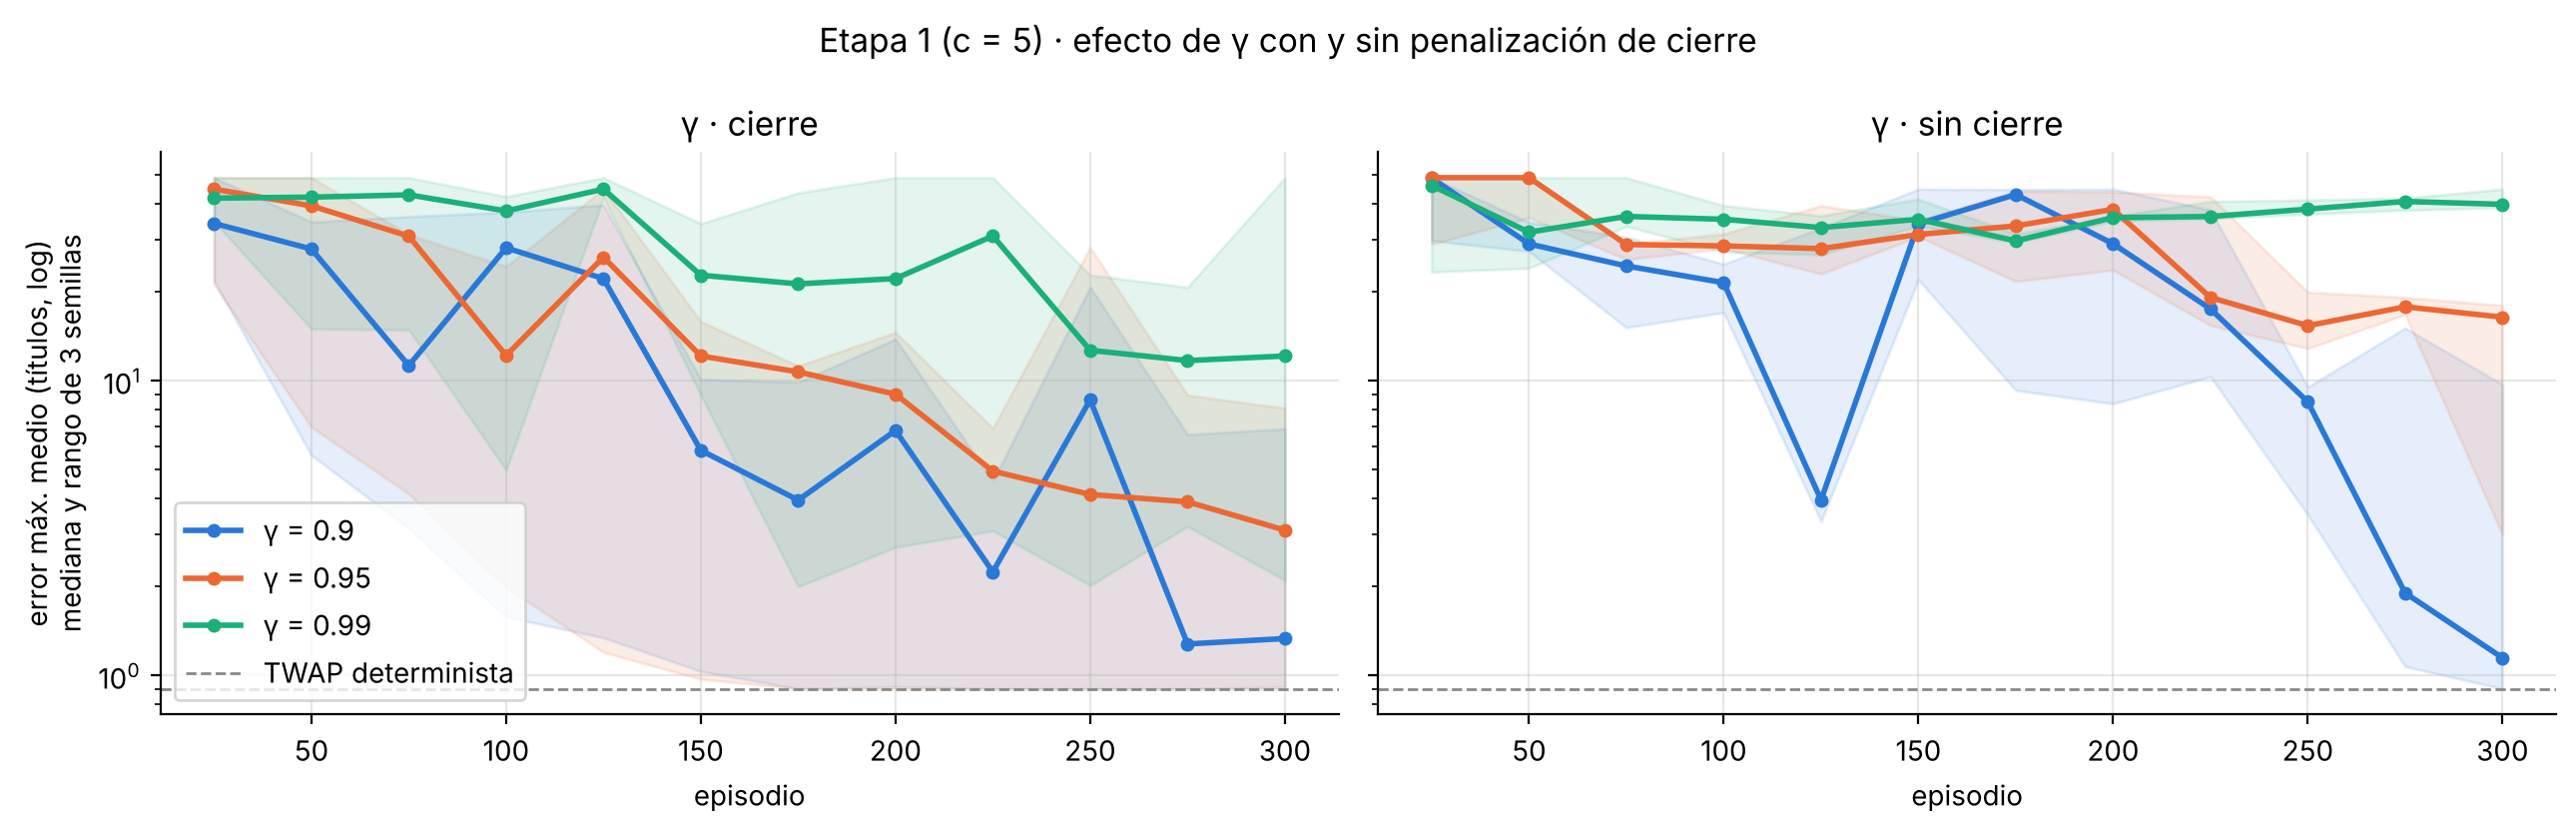

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, param in zip(axes, ["gamma · cierre", "gamma · sin cierre"]):
    for value, col in [("0.9", C["azul"]), ("0.95", C["naranja"]), ("0.99", C["aqua"])]:
        cv = curvas[(curvas.param == param) & (curvas.value == value)].pivot(index="episode", columns="seed", values="max_err")
        ax.plot(cv.index, cv.median(axis=1), "o-", ms=4, color=col, label=f"γ = {value}")
        ax.fill_between(cv.index, cv.min(axis=1), cv.max(axis=1), color=col, alpha=0.12)
    ax.axhline(twap_grid.max_err.mean(), color=C["gris"], ls="--", lw=1, label="TWAP determinista")
    ax.set_yscale("log"); ax.set_xlabel("episodio"); ax.set_title(param.replace("gamma", "γ"))
axes[0].set_ylabel("error máx. medio (títulos, log)\nmediana y rango de 3 semillas"); axes[0].legend()
fig.suptitle("Etapa 1 (c = 5) · efecto de γ con y sin penalización de cierre"); fig.tight_layout()
pl.save(fig, "ej2_barrido_gamma")

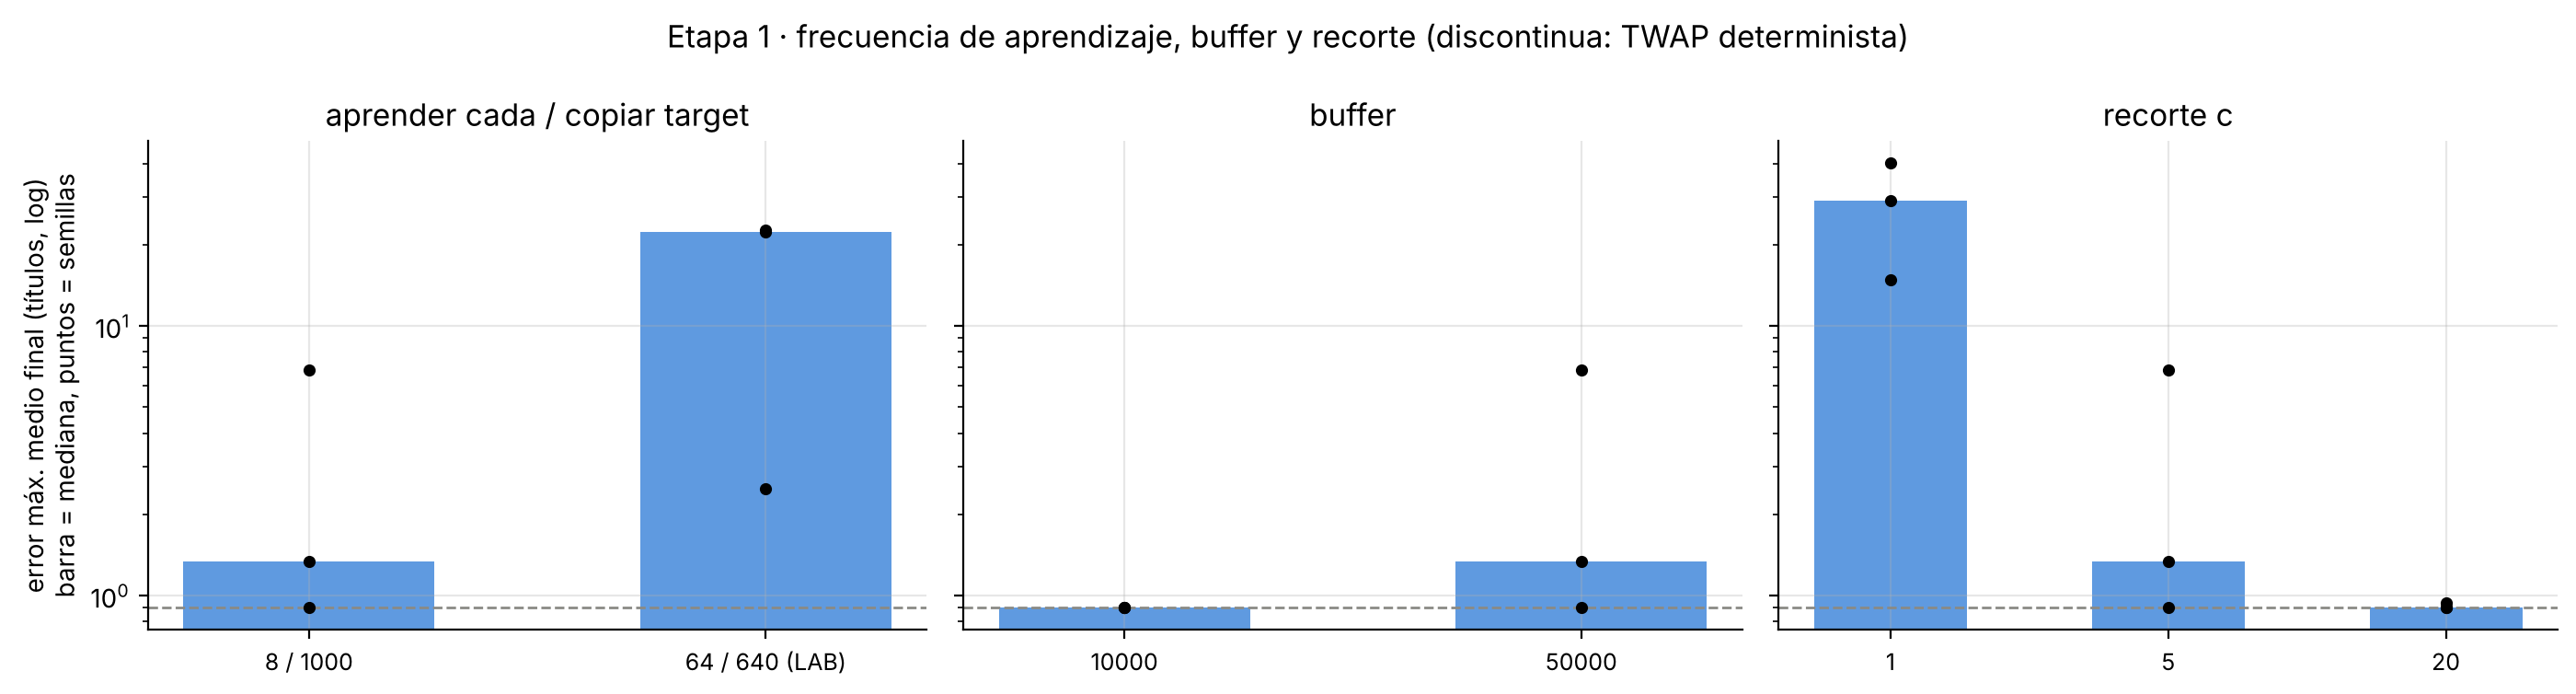

In [19]:
fig = plot_bars(sw1, ["aprender cada / copiar target", "buffer", "recorte c"],
                "Etapa 1 · frecuencia de aprendizaje, buffer y recorte (discontinua: TWAP determinista)", "ej2_barrido_etapa1")

**Lo que dice la etapa 1:**

| Parámetro | Resultado (error máximo medio, 3 semillas) | Lectura |
|---|---|---|
| **γ con cierre** | 0,9 → 3,04 · 0,95 → 4,03 · 0,99 → 21,0 | Peor cuanto más alto |
| **γ sin cierre** | 0,9 → 3,92 · 0,95 → 12,5 · 0,99 → 41,0, y acaba al 93 %, 77 % y **17 %** del tiempo | Con γ alto aparece el atajo de §1: el agente termina la orden lo antes posible |
| **Aprender cada 64 / copiar cada 640** (LAB) | 15,8; ninguna semilla baja de 2 títulos ni completa órdenes | Muy pocas actualizaciones (~8 por episodio) |
| **Buffer 10.000** | 0,90 en las 3 semillas, frente a 3,04 | Mejor que el valor de partida |
| **Recorte c** | 1 → 28,0 · 5 → 3,04 · **20 → 0,91** en las 3 semillas | c = 5 era mala elección |

**γ tiene dos efectos y el barrido los separa.** Con γ = 0,99, quitar el cierre lleva al agente a acabar al 17 % del tiempo,
y ponerlo lo devuelve al 100 %: **el cierre arregla el atajo**. Pero aun con cierre γ = 0,99 se queda en 21 títulos: **el
segundo efecto es la escala**. Con un horizonte de 100 pasos, la diferencia entre comprar y esperar en un paso concreto es
pequeña frente al valor de Q, que suma recompensas de 100 pasos con decisiones futuras ruidosas, y la red no la distingue en
300 episodios. Con γ = 0,9 el horizonte (~10 pasos) coincide con la separación entre compras, que es lo que hay que ver.

**La configuración de partida era inestable.** Con c = 5 y buffer de 50.000, las semillas dan 0,90, 1,33 y 6,87 títulos, y
dos de las tres dejan 1-2 títulos sin ejecutar (solo el 33 % de órdenes completas). Con c = 1 todo lo que el agente ve en los
primeros episodios, lejos del plan, cobra el mismo −1: no hay gradiente hacia la diagonal y no aprende. Con c = 20 la
recompensa es informativa en casi todo el rango, y las tres semillas llegan a 0,90-0,94 y bajan de 2 títulos hacia el
episodio 92. **Se cambia a c = 20**, y la etapa 2 repite el resto desde ahí.

### 6.4 Etapa 2 · Desde c = 20

Se repiten desde c = 20 los parámetros que la etapa 1 no deja cerrados: el buffer (10.000 fue mejor con c = 5, ¿lo sigue
siendo?), γ con y sin cierre (¿el fallo de γ alto era solo el atajo?) y la frecuencia de aprendizaje.

In [20]:
BASE1 = {**BASE0, "clip": C_FINAL}
ETAPA2 = {
    ("buffer", 10_000): {"buffer_size": 10_000},
    ("buffer", 50_000): {},
    ("gamma · cierre", 0.9): {},
    ("gamma · cierre", 0.95): {"gamma": 0.95},
    ("gamma · cierre", 0.99): {"gamma": 0.99},
    ("gamma 0.99 · sin cierre", 0.99): {"reward": "seguimiento", "gamma": 0.99},
    ("aprender cada / copiar target", "8 / 1000"): {},
    ("aprender cada / copiar target", "64 / 640 (LAB)"): {"learn_after": 64, "update_target_after": 640},
}
sw2, curvas2, tabla2 = sweep("ej2_sweeps_etapa2", ETAPA2, BASE1)
tabla2.round(2)

error_max  peor_semilla  \
param                         value                                     
buffer                        10000                0.90          0.90   
                              50000                0.91          0.94   
gamma · cierre                0.9                  0.91          0.94   
                              0.95                 1.18          1.66   
                              0.99                 4.57          7.07   
gamma 0.99 · sin cierre       0.99                 8.16         16.95   
aprender cada / copiar target 8 / 1000             0.91          0.94   
                              64 / 640 (LAB)       6.29          8.72   

                                              mejor_semilla  acaba_en  \
param                         value                                     
buffer                        10000                    0.90      0.99   
                              50000                    0.90      0.99   
gamma · cierre                0.9                      0.90      0.99   
                              0.95                     0.90      0.99   
                              0.99                     1.59      1.00   
gamma 0.99 · sin cierre       0.99                     2.70      0.85   
aprender cada / copiar target 8 / 1000                 0.90      0.99   
                              64 / 640 (LAB)           2.61      1.00   

                                              completas  primer_ep_bajo_2  \
param                         value                                         
buffer                        10000                1.00             75.00   
                              50000                1.00             91.67   
gamma · cierre                0.9                  1.00             91.67   
                              0.95                 0.67            166.67   
                              0.99                 0.56            225.00   
gamma 0.99 · sin cierre       0.99                 0.93               NaN   
aprender cada / copiar target 8 / 1000             1.00             91.67   
                              64 / 640 (LAB)       0.00               NaN   

                                              semillas_que_llegan  
param                         value                                
buffer                        10000                             3  
                              50000                             3  
gamma · cierre                0.9                               3  
                              0.95                              3  
                              0.99                              1  
gamma 0.99 · sin cierre       0.99                              0  
aprender cada / copiar target 8 / 1000                          3  
                              64 / 640 (LAB)                    0

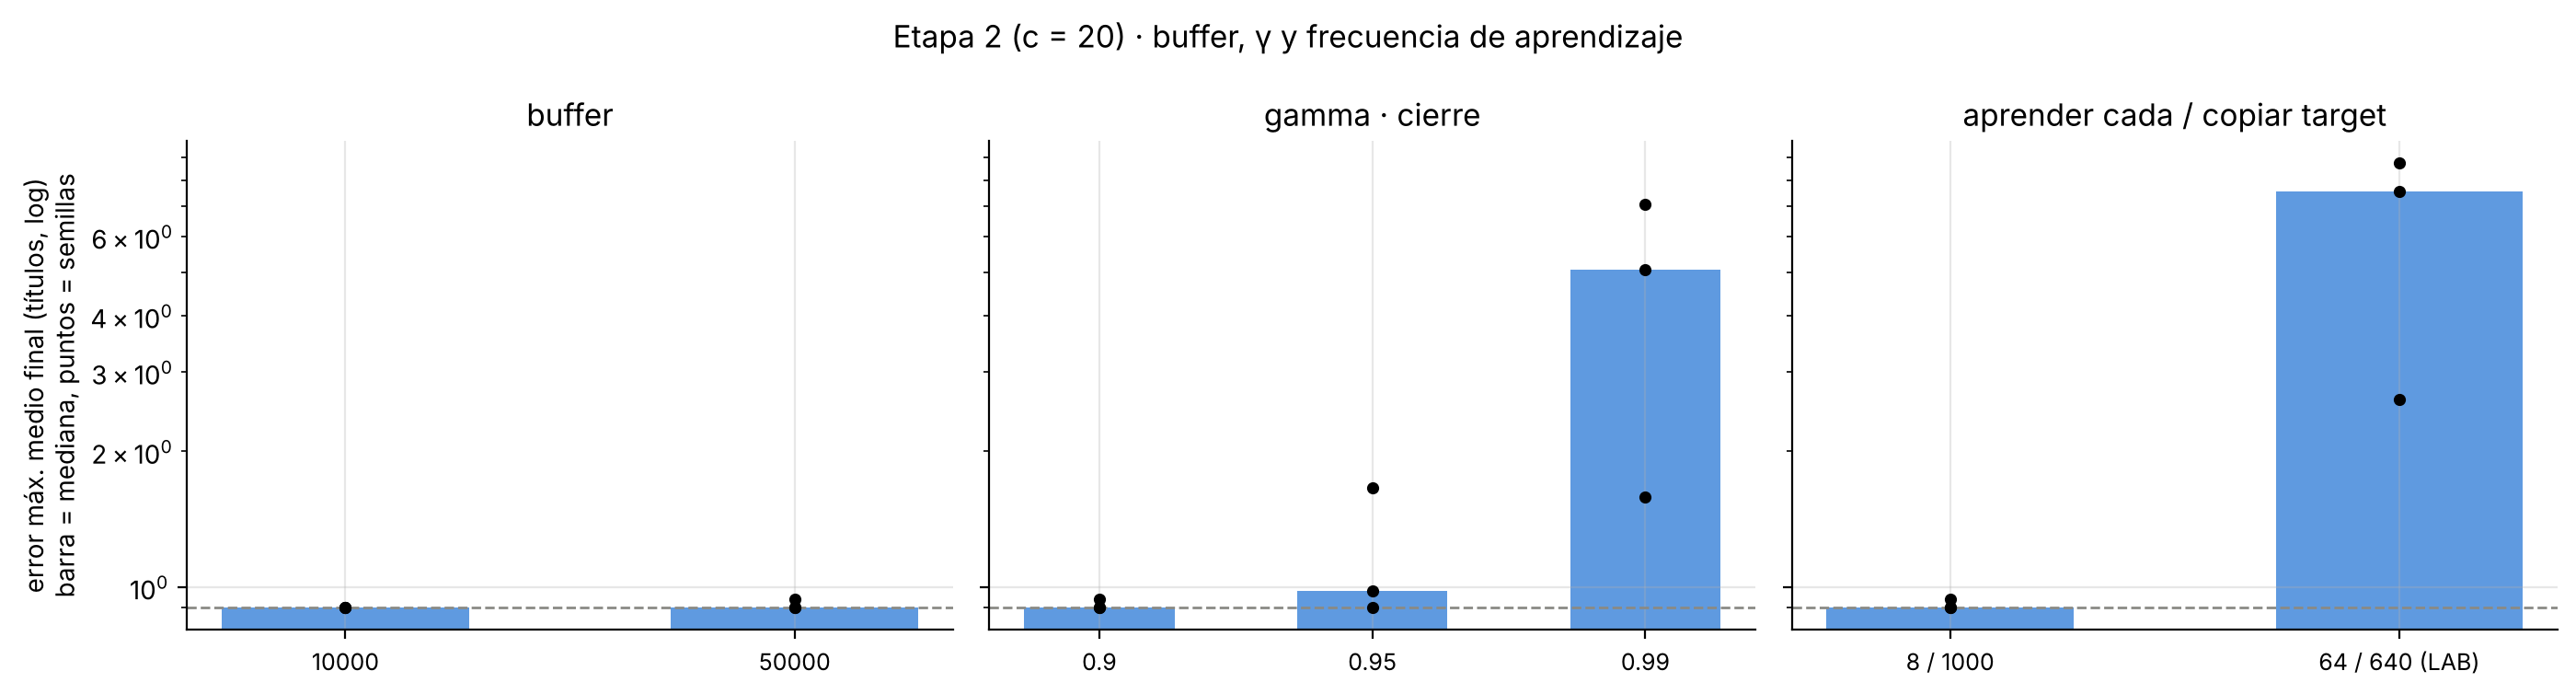

In [21]:
fig = plot_bars(sw2, ["buffer", "gamma · cierre", "aprender cada / copiar target"],
                "Etapa 2 (c = 20) · buffer, γ y frecuencia de aprendizaje", "ej2_barrido_etapa2")

**Lo que dice la etapa 2 (desde c = 20):**

- **Buffer.** 10.000 da 0,90 en las tres semillas y baja de 2 títulos hacia el episodio 75; 50.000 da 0,90-0,94 y lo hace
  hacia el 92. Con c = 20 los dos funcionan, pero **10.000 es igual o mejor en cada semilla y en las dos etapas**. La razón
  más probable: el buffer pequeño olvida antes los 25 episodios aleatorios de llenado y la política mala del principio, y la
  red aprende antes de la experiencia cercana a la diagonal. El riesgo habitual de un buffer pequeño, el olvido
  catastrófico de situaciones raras, aquí es bajo: la política óptima es la misma todos los días, porque no depende del
  mercado. Y 10.000 pasos son ~20 episodios distintos, de modo que cada batch sigue mezclando días, duraciones y tamaños.
  **Se elige 10.000.**
- **γ.** 0,9 → 0,91 (las tres semillas bien); 0,95 → 1,18 (una semilla en 1,66 que deja órdenes sin completar); 0,99 → 4,57
  (solo una semilla baja de 2 títulos, y en el episodio 225); 0,99 sin cierre → 8,16, acabando al 85 % del tiempo. Con la
  recompensa ya corregida se mantiene la conclusión: **γ = 0,9**.
- **Frecuencia de aprendizaje.** La del LAB (64 / 640) da 6,29 y ninguna semilla baja de 2 títulos ni completa órdenes.
  **Se mantiene 8 / 1.000.**
- **Episodios.** Con la configuración final, las tres semillas bajan de 2 títulos entre los episodios 50 y 125, y el modelo de
  §4 está en 0,90 desde el episodio 100. Se mantienen **300**, que dan margen y llegan a ε mínimo en el 150. El ej. 3 cambia
  justo esto: que la exploración baje cuando el agente mejora y no por el número de episodios.

### 6.5 Parametría final

| Parámetro | Partida | Final | Evidencia |
|---|---|---|---|
| γ | 0,9 (razonado: horizonte ≈ N/n) | **0,9** | Etapas 1 y 2: 0,95 y 0,99 empeoran con y sin cierre |
| Cierre | — | **Sí** | Con γ = 0,99 evita acabar al 17 % del tiempo; recompensa correcta para cualquier γ |
| Recorte c | 5 | **20** | 3,04 → 0,91 de error medio entre semillas; c = 1 no aprende |
| Buffer | 50.000 (regla de ~100 episodios) | **10.000** | Igual o mejor en todas las semillas, aprende antes |
| Aprender cada / copiar target | 8 / 1.000 | **8 / 1.000** | 64 / 640 no aprende en 300 episodios |
| Episodios | 300 | **300** | Converge entre los episodios 50 y 125 |

## 7. Conclusiones

**Parte 1 · Estado y recompensa.**

- El estado `[T, V]` basta: la regla del TWAP es la diagonal de ese plano, la desviación respecto al plan es `n·(T − V)` y,
  al estar normalizado, episodios de cualquier día, hora, duración y tamaño son el mismo problema.
- La recompensa por defecto mide un slippage frente a un VWAP futuro, ~10⁻⁴ por compra e imposible de prever con `[T, V]`.
  No distingue un TWAP de comprar todo al final.
- La recompensa elegida, **seguimiento del plan con cierre**, penaliza en cada paso la distancia al plan en títulos
  (recortada en 20) y cobra al terminar los pasos que faltan. El cierre elimina un atajo real: sin él, completar la orden
  pronto apaga la penalización, y con γ alto el agente lo aprende.
- **El agente replica el TWAP** en los 27 episodios de la rejilla: completa todas las órdenes, acaba al 98,9 % del tiempo,
  compra cada N/n pasos (intervalo relativo 1,01 ± 0,07) y tiene el mismo error máximo que el TWAP determinista (0,90, todo
  él debido a la compra forzada del paso 0) con un error medio menor (0,27 frente a 0,44), porque oscila centrado en el plan
  en lugar de ir siempre adelantado. Llega a ese punto hacia el episodio 50-100.

**Parte 2 · Parametría.**

- **γ = 0,9:** horizonte efectivo de ~10 pasos, la separación entre compras. Con γ alto aparecen dos problemas que el barrido
  separa: el atajo de terminar pronto (lo arregla el cierre) y una diferencia entre acciones enterrada en Q-valores grandes
  (no lo arregla nada salvo bajar γ).
- **El barrido corrigió dos decisiones razonadas a priori:** el recorte (5 → 20), porque una recompensa que satura cerca del
  plan no dice al agente cómo volver cuando está lejos, y el buffer (50.000 → 10.000), porque olvidar antes la experiencia
  aleatoria del principio acelera y estabiliza el aprendizaje en un problema estacionario.
- **Aprender cada 8 pasos** en lugar de cada 64: con la frecuencia del LAB no hay actualizaciones suficientes en 300 episodios.

**Limitaciones.**

- El error máximo no baja del 0,90 del TWAP determinista por la compra forzada del paso 0, y el agente no llega al 0,5 del
  oráculo porque n no está en el estado. Añadirlo (o `V − T` escalado por n) es la mejora natural si se quisiera un
  seguimiento más fino.
- Se evalúa en train, como permite el enunciado. Como la política no usa ninguna variable de mercado, cabe esperar el mismo
  comportamiento en val y test.
- Las conclusiones del barrido se apoyan en 3 semillas: valen para diferencias grandes (c = 5 frente a 20, γ = 0,9 frente a
  0,99) y no tanto para las pequeñas (buffer de 10.000 frente a 50.000 con c = 20).